#

# 12. Support Vector Machine

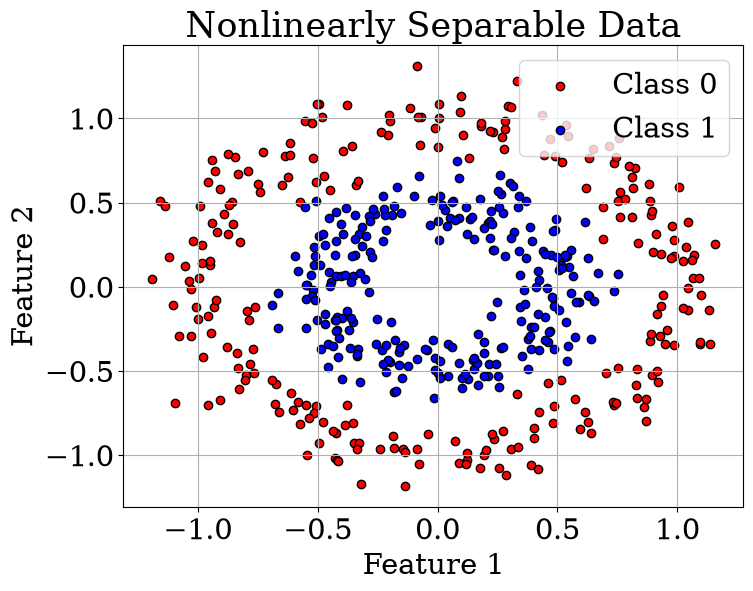

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
plt.rcParams['font.family'] = 'Serif'
plt.rcParams['font.size'] = 21

# Generate nonlinearly separable data
X, y = make_circles(n_samples=500, noise=0.1, factor=0.5, random_state=42)

# Plot the data
plt.figure(figsize=(8, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], color='red', label='Class 0', edgecolors='k')
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='blue', label='Class 1', edgecolors='k')
plt.title('Nonlinearly Separable Data')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.grid(True)

# Save the plot as a PDF
plt.savefig('figures/nonlinearly_separable_data.pdf', format='pdf')

# Show the plot
plt.show()

# Hyperplane Equation

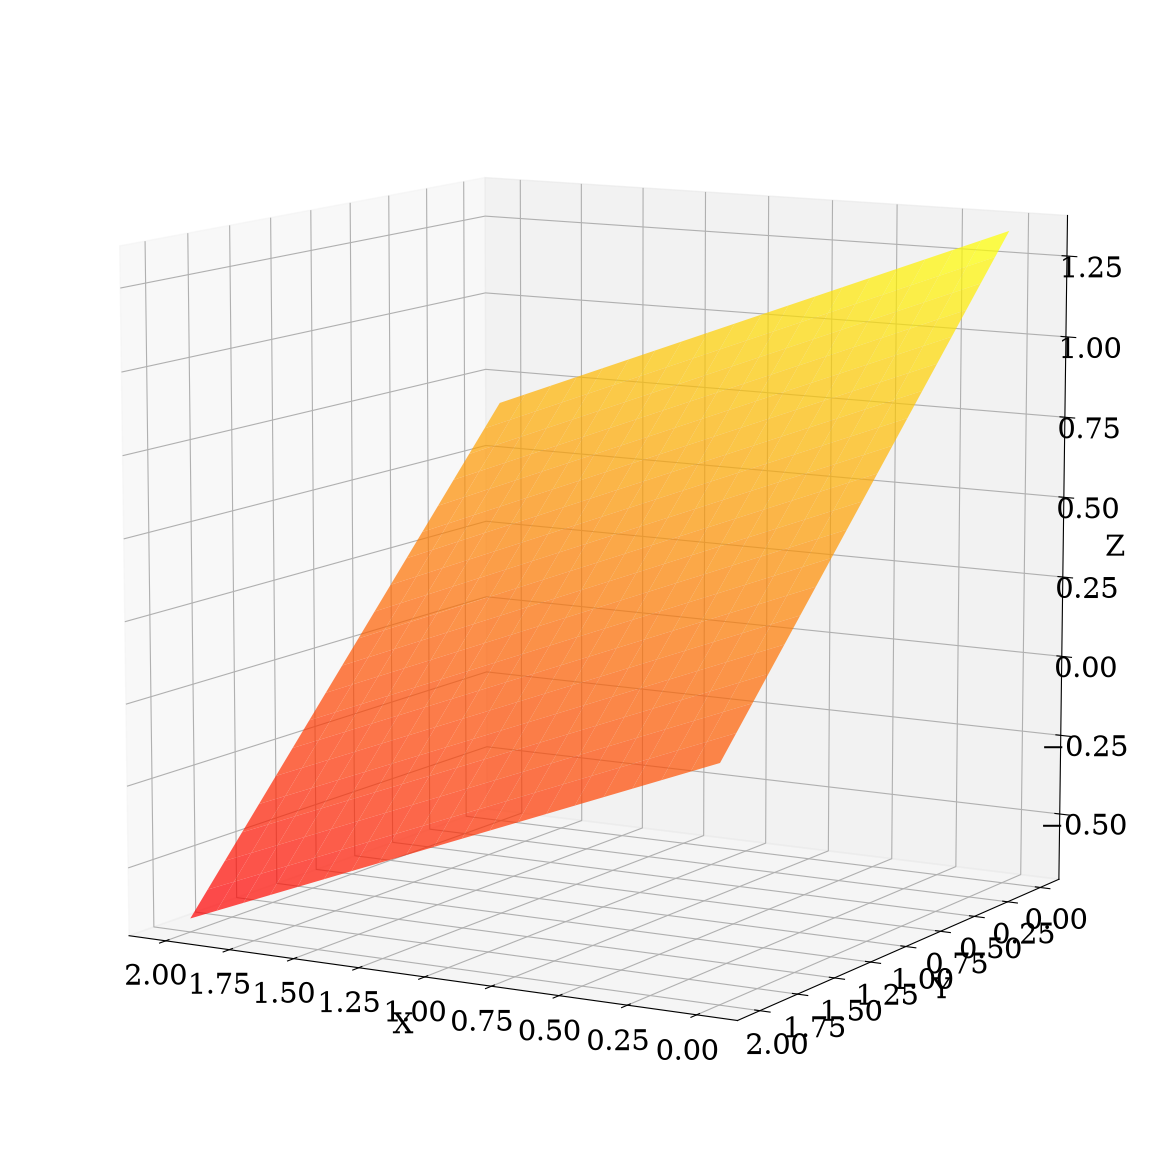

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define the hyperplane parameters
w = np.array([1, 2, 3])
beta = 4

# Choose a point x0 in 3D space
x0 = np.array([1, 1, 2])

# Calculate the projection of x0 onto the hyperplane
w_dot_x0 = np.dot(w, x0)
numerator = w_dot_x0 - beta
denominator = np.dot(w, w)
proj = x0 - (numerator / denominator) * w

# Create a meshgrid for the hyperplane
x = np.linspace(0, 2, 20)
y = np.linspace(0, 2, 20)
X, Y = np.meshgrid(x, y)
Z = (beta - w[0]*X - w[1]*Y) / w[2]

# Create the 3D plot
fig = plt.figure(figsize=(15, 15))
ax = fig.add_subplot(111, projection='3d')

# Plot the hyperplane with red-yellow colormap
surf = ax.plot_surface(X, Y, Z, cmap='autumn', alpha=0.7)


# Set labels and legend
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')

ax.view_init(elev=10, azim=120) 
ax.set_box_aspect((1, 1, 1))

# Save the figure as PDF
plt.savefig('figures/hyperplane.pdf', format='pdf', bbox_inches='tight')

plt.show()

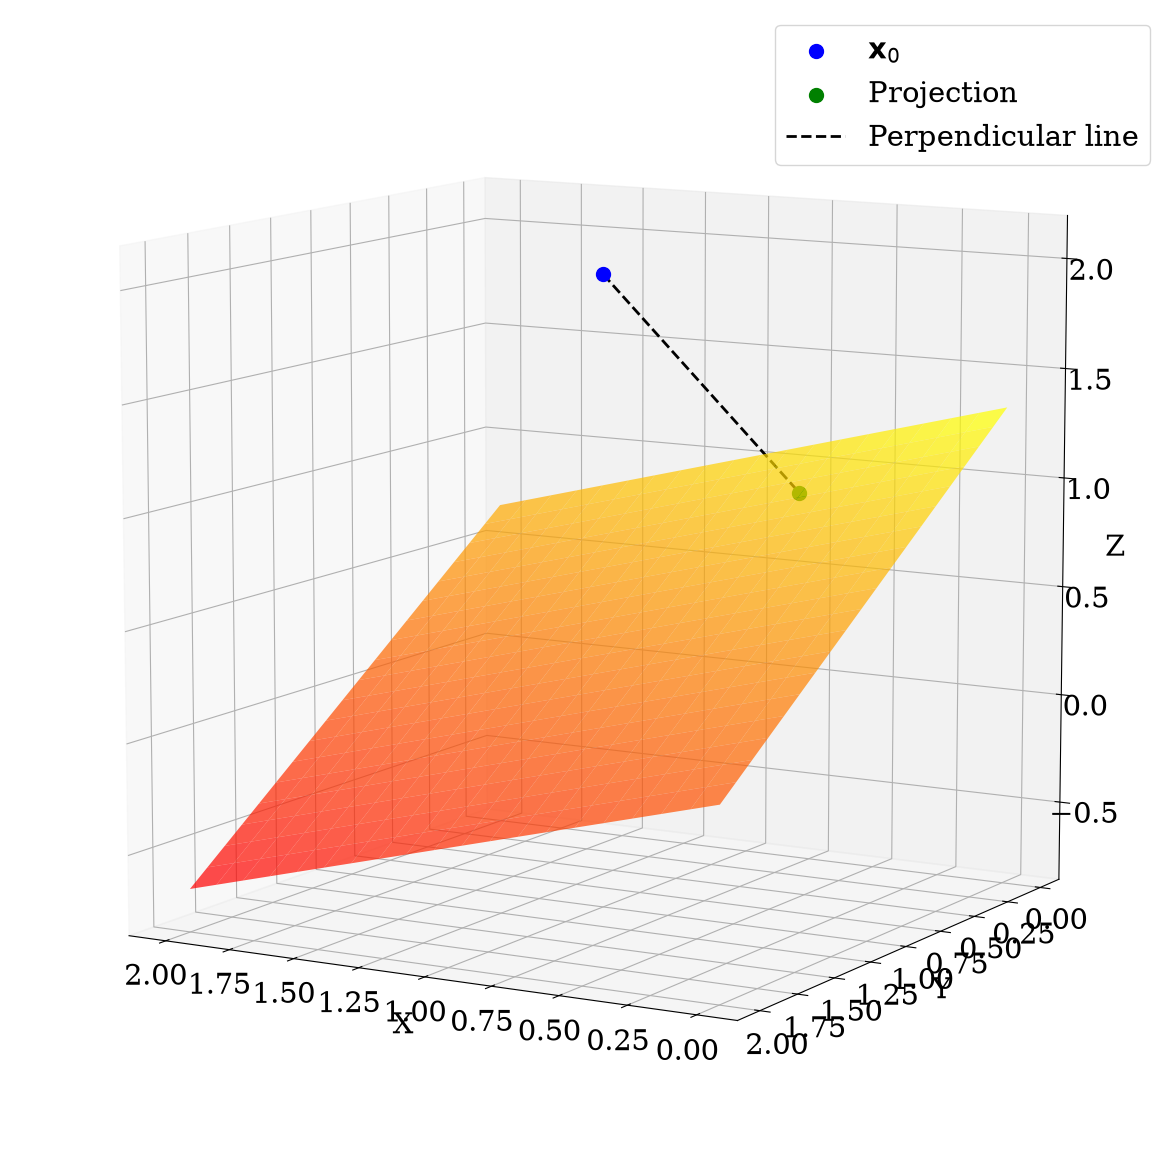

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define the hyperplane parameters
w = np.array([1, 2, 3])
beta = 4

# Choose a point x0 in 3D space
x0 = np.array([1, 1, 2])

# Calculate the projection of x0 onto the hyperplane
w_dot_x0 = np.dot(w, x0)
numerator = w_dot_x0 - beta
denominator = np.dot(w, w)
proj = x0 - (numerator / denominator) * w

# Create a meshgrid for the hyperplane
x = np.linspace(0, 2, 20)
y = np.linspace(0, 2, 20)
X, Y = np.meshgrid(x, y)
Z = (beta - w[0]*X - w[1]*Y) / w[2]

# Create the 3D plot
fig = plt.figure(figsize=(15, 15))
ax = fig.add_subplot(111, projection='3d')

# Plot the hyperplane with red-yellow colormap
surf = ax.plot_surface(X, Y, Z, cmap='autumn', alpha=0.7)

# Plot the original point and its projection
ax.scatter(*x0, color='blue', s=100, label='$\\mathbf{x}_0$')
ax.scatter(*proj, color='green', s=100, label='Projection')

# Draw the perpendicular line connecting x0 to its projection
ax.plot([x0[0], proj[0]], [x0[1], proj[1]], [x0[2], proj[2]], 
        color='black', linestyle='--', linewidth=2, label='Perpendicular line')

# Set labels and legend
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.legend()
ax.view_init(elev=10, azim=120) 
ax.set_box_aspect((1, 1, 1))  

# Save the figure as PDF
plt.savefig('figures/hyperplane_projection.pdf', format='pdf', bbox_inches='tight')

plt.show()

# 1. SVM: Linear Hyperplane Separation

### Problem: Generate a linearly separarelable dataset consisting of two class, implement support vector machine to separate them. Also create plot in matplotlib to visualize the maximum separation and support vectors.

### Steps:

- **Generate a Linearly Separable Dataset:** We’ll create a synthetic dataset with two classes that are linearly separable. For demonstration purposes, we'll generate random data points using make_blobs from sklearn.datasets.
- **Implement Support Vector Machine (SVM):** We’ll use the `LinearSVC` class from `sklearn.sv`m to train an SVM model on our dataset. This classifier aims to find the optimal hyperplane that maximizes the separation between the two classes.
- **Visualize the Decision Boundary and Support Vectors:** We’ll plot the decision boundary and highlight the support vectors.

## Generation Synethetic Dataset

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import LinearSVC
from sklearn.inspection import DecisionBoundaryDisplay
plt.rcParams['font.family'] = 'Serif'
plt.rcParams['font.size'] = 21


# Generate a linearly separable dataset
X, y = make_blobs(n_samples=100, centers=[[2, 2], [-3, -2]], random_state=0)

# Train a Linear SVM

In [5]:

## The large value of C means clearly seaprable case
clf = LinearSVC(C=1e6, loss="hinge", random_state=42, dual="auto").fit(X, y)

# Obtain the support vectors

In [6]:
decision_function = clf.decision_function(X)
support_vector_indices = np.where(np.abs(decision_function) <= 1 + 1e-15)
support_vectors = X[support_vector_indices]


# Plot the data points and decision boundary

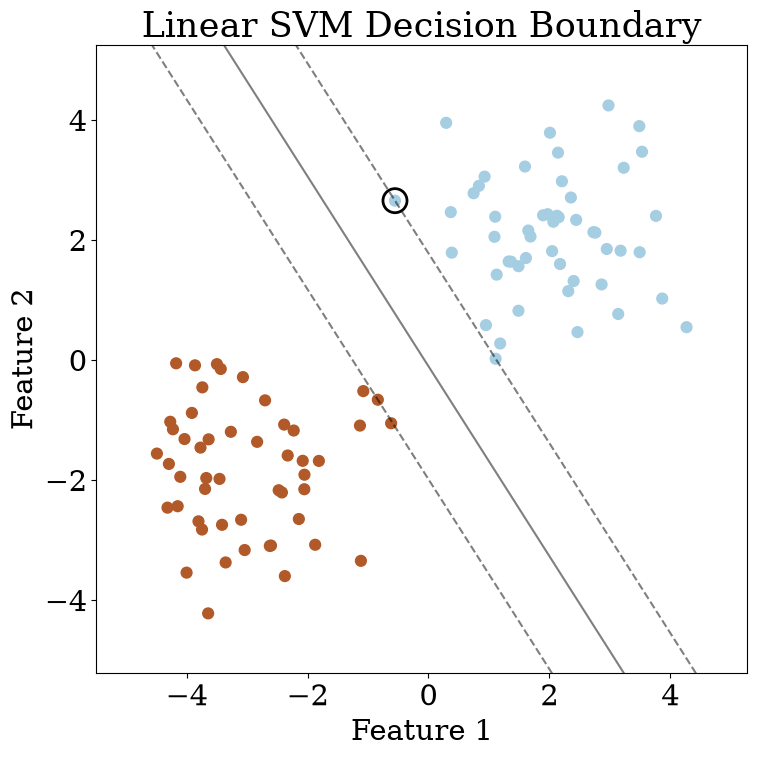

In [7]:
plt.figure(figsize=(8, 8))
plt.scatter(X[:, 0], X[:, 1], c=y, s=60, cmap=plt.cm.Paired)
ax = plt.gca()
DecisionBoundaryDisplay.from_estimator(
    clf,
    X,
    ax=ax,
    grid_resolution=50,
    plot_method="contour",
    colors="k",
    levels=[-1, 0, 1],
    alpha=0.5,
    linestyles=["--", "-", "--"],
)
plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=300, linewidth=2, facecolors="none", edgecolors="k")
plt.title("Linear SVM Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
#plt.axis('equal')

plt.show()


# 2. SVM: Linear Hyperplane with Fuzzy Separation

# Generate dataSet that may need some misclassfication

In [8]:
# Generate a linearly separable dataset
X, y = make_blobs(n_samples=200, centers=2, random_state=0)

# Train SVM

## Set C = 1 for penalty (regularzation)

In [9]:
clf = LinearSVC(C=1, loss="hinge", random_state=42, dual="auto", max_iter=2000).fit(X, y)


# Obtain the Support Vectors and Plot

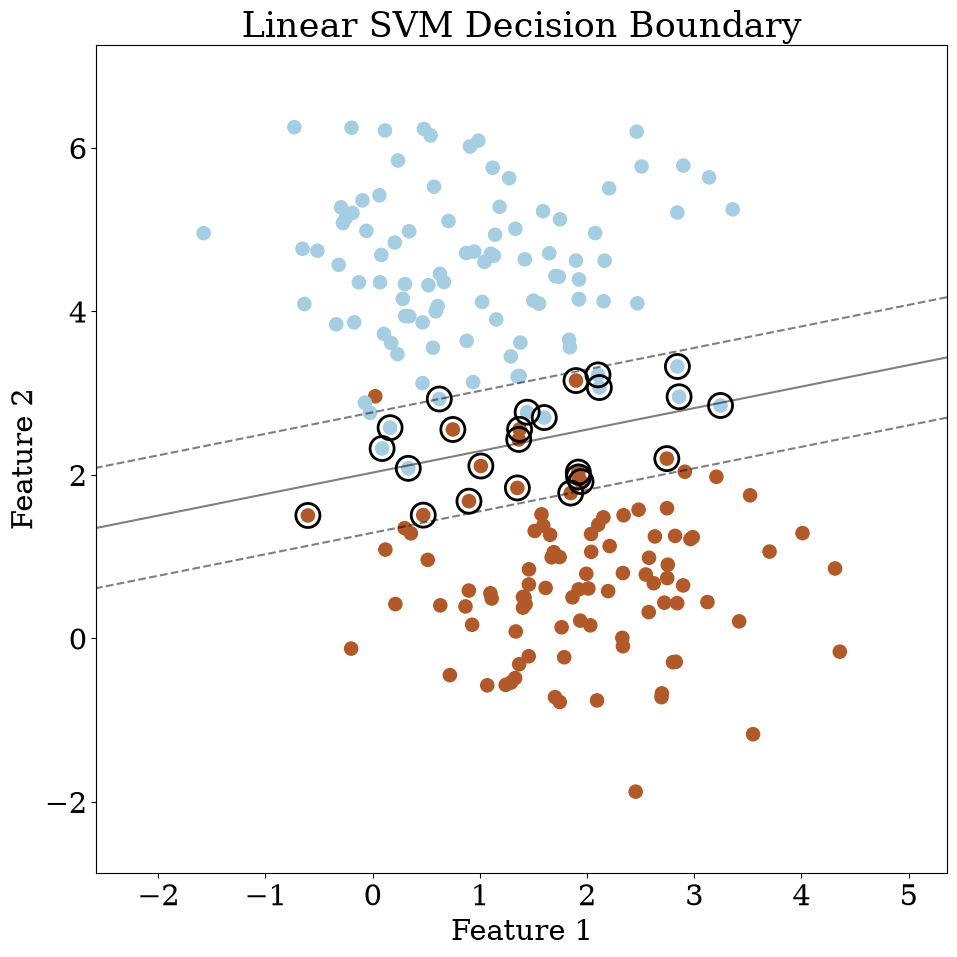

In [10]:
decision_function = clf.decision_function(X)
support_vector_indices = np.where(np.abs(decision_function) <= 1 + 1e-15)
support_vectors = X[support_vector_indices]

# Plot the data points and decision boundary
plt.figure(figsize=(10, 10))
plt.scatter(X[:, 0], X[:, 1], c=y, s=90, cmap=plt.cm.Paired)
ax = plt.gca()
DecisionBoundaryDisplay.from_estimator(
    clf,
    X,
    ax=ax,
    grid_resolution=50,
    plot_method="contour",
    colors="k",
    levels=[-1, 0, 1],
    alpha=0.5,
    linestyles=["--", "-", "--"],
)
plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=300, linewidth=2, facecolors="none", edgecolors="k")
plt.title("Linear SVM Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()

# 3. Image Classification using SVM

In this notebook, we will read a folder containing two subfolders to train an SVM Classifier to distinguish between images of cats and dogs.
As images are not of the same size, we will be resizing them using OpenCV python package.


In [11]:
from PIL import Image
import os
import numpy as np
from sklearn import svm
from sklearn.model_selection import train_test_split

# Define function to load images from given directories


In [12]:
def load_images_from_folder(folder):
    images = []
    for filename in os.listdir(folder):
        try:
            img = Image.open(os.path.join(folder, filename))
            img = img.resize((64, 64))
            img = img.convert('RGB')
            images.append(np.array(img))
        except:
            pass
    return images

# Load images

In [23]:
cats = load_images_from_folder('../../Datasets/CatsDogs/PetImages/Cat_Small/')
dogs = load_images_from_folder('../../Datasets/CatsDogs/PetImages/Dog_Small/')

# Create Labels and Combine Data

In [24]:
# Create labels
labels = [0]*len(cats) + [1]*len(dogs)

# Combine data
data = cats + dogs

# Flatten Image and Normalize it

In [25]:
data = [i.flatten() for i in data]
data = np.array(data) / 255.0

# Split data into training and testing sets


In [26]:
X_train, X_test, y_train, y_test = train_test_split(data, labels, test_size=0.2, random_state=42)


# Train SVM

In [27]:
clf = svm.SVC()
clf.fit(X_train, y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


# Test Accuracy

In [28]:
print('Test Accuracy: ', clf.score(X_test, y_test))

Test Accuracy:  0.6125


# Predict a new image

In [30]:
import numpy as np

new_image = Image.open('../../Datasets/CatsDogs/dog.jpg')
new_image = new_image.resize((64, 64))
new_image = new_image.convert('RGB')  # Ensure consistent color format
new_image = np.array(new_image).flatten() / 255.0
print('Prediction: ', 'Dog' if clf.predict([new_image]) else 'Cat')

Prediction:  Dog


In [31]:
new_image = Image.open('../../Datasets/CatsDogs/cat.jpg')
new_image = new_image.resize((64, 64))
new_image = new_image.convert('RGB')  # Ensure consistent color format
new_image = np.array(new_image).flatten() / 255.0
print('Prediction: ', 'Dog' if clf.predict([new_image]) else 'Cat')

Prediction:  Dog


# 4. Nonlinear Separation

### Problem: Generate halfmoon dataset consisting of two class, implement support vector machine to separate them. Also create plot in matplotlib to visualize the maximum separation and support vectors.

## Generation Synethetic Dataset

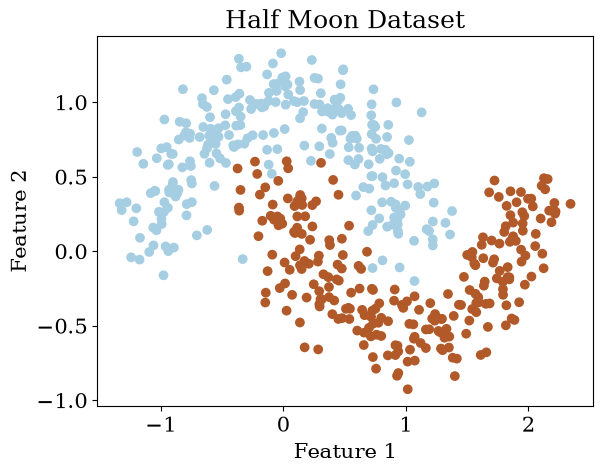

In [32]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Serif'
plt.rcParams['font.size'] = 15


from sklearn.datasets import make_moons

# Generate the half moon dataset
X, y = make_moons(n_samples=500, noise=0.18, shuffle=False)


# Plot the dataset
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired)
plt.title("Half Moon Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


# Train a nonLinear SVM

We’ll use the Support Vector Machine (SVM) algorithm to classify the data. Scikit-learn provides different SVM classifiers, including SVC (for linear kernel), NuSVC, and LinearSVC. Additionally, we’ll explore three different kernel functions: polynomial, Gaussian (RBF), and sigmoid.

In [33]:
from sklearn.svm import SVC, NuSVC, LinearSVC

# Initialize SVM classifiers
clf_linear = SVC(kernel='linear')
clf_poly = SVC(kernel='poly', degree=4, coef0=1, C=5)
clf_rbf = SVC(kernel='rbf', gamma=5, C=0.001)
clf_sigmoid = SVC(kernel='sigmoid', coef0=0.3)

# Fit the classifiers to the data
clf_linear.fit(X, y)
clf_poly.fit(X, y)
clf_rbf.fit(X, y)
clf_sigmoid.fit(X, y)


,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'sigmoid'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.3
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


# Plot the decision function for linear seapration

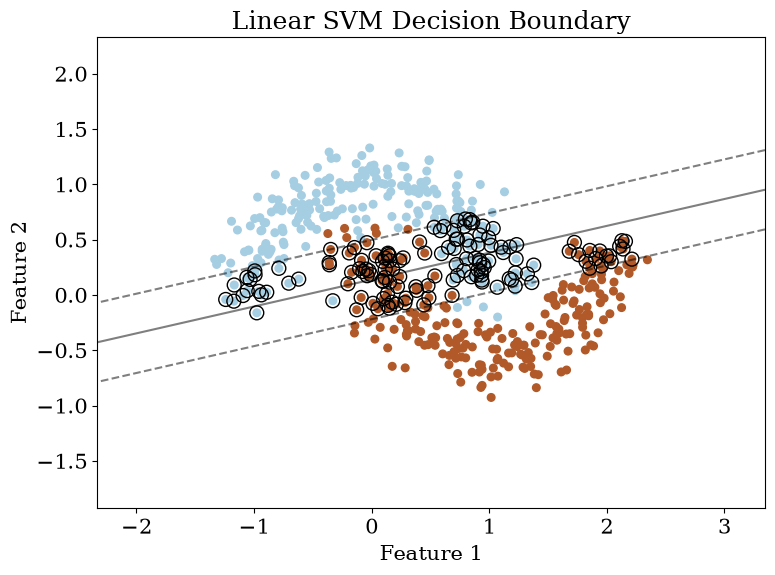

In [34]:
from sklearn.inspection import DecisionBoundaryDisplay
decision_function = clf_linear.decision_function(X)
support_vector_indices = np.where(np.abs(decision_function) <= 1 + 1e-15)
support_vectors = X[support_vector_indices]

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=30, cmap=plt.cm.Paired)
ax = plt.gca()
DecisionBoundaryDisplay.from_estimator(
    clf_linear,
    X,
    ax=ax,
    grid_resolution=50,
    plot_method="contour",
    colors="k",
    levels=[-1, 0, 1],
    alpha=0.5,
    linestyles=["--", "-", "--"],
)
plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=100, linewidth=1, facecolors="none", edgecolors="k")
plt.title("Linear SVM Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.tight_layout()
plt.show()


# Plot the decision function for polynomial seapration

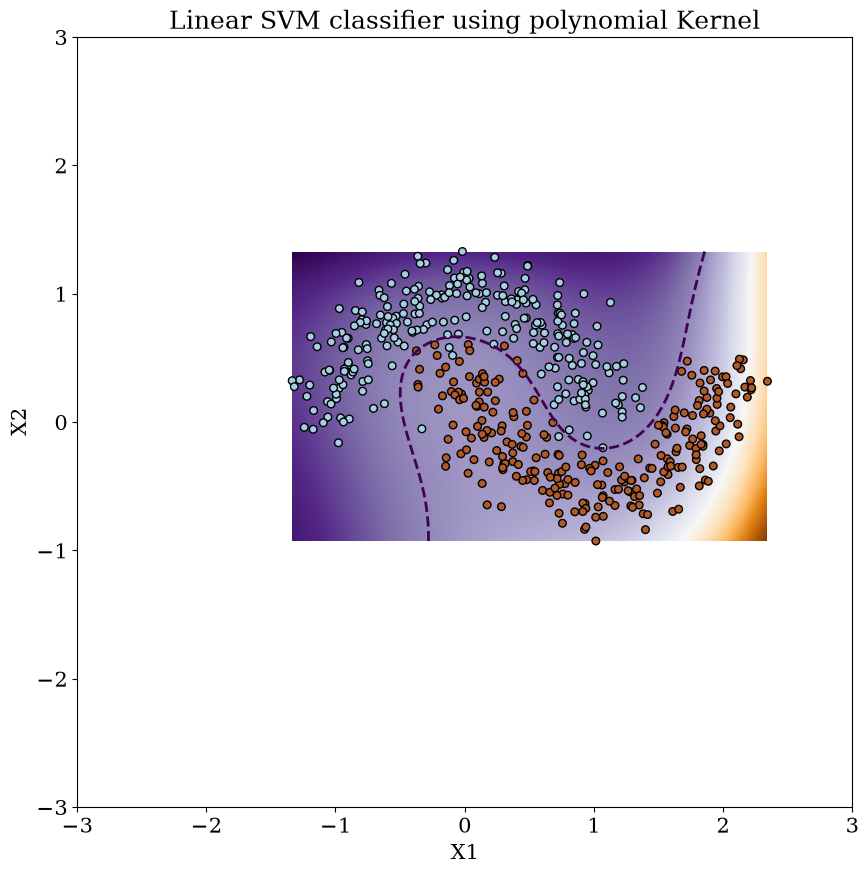

In [35]:
xx, yy = np.meshgrid(np.linspace(X[:, 0].min(), X[:, 0].max(), 500),
                     np.linspace(X[:, 1].min(), X[:, 1].max(), 500))

Z_poly = clf_poly.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z_poly = Z_poly.reshape(xx.shape)

plt.figure(figsize=(10,10))
plt.imshow(
    Z_poly,
    interpolation="nearest",
    extent=(xx.min(), xx.max(), yy.min(), yy.max()),
    aspect="auto",
    origin="lower",
    cmap=plt.cm.PuOr_r,
)
contours = plt.contour(xx, yy, Z_poly, levels=[0], linewidths=2, linestyles="dashed")
plt.scatter(X[:, 0], X[:, 1], s=30, c=y, cmap=plt.cm.Paired, edgecolors="k")
plt.axis([-3, 3, -3, 3])
plt.title('Linear SVM classifier using polynomial Kernel')
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()


# Plot the decision function for RBF kernel

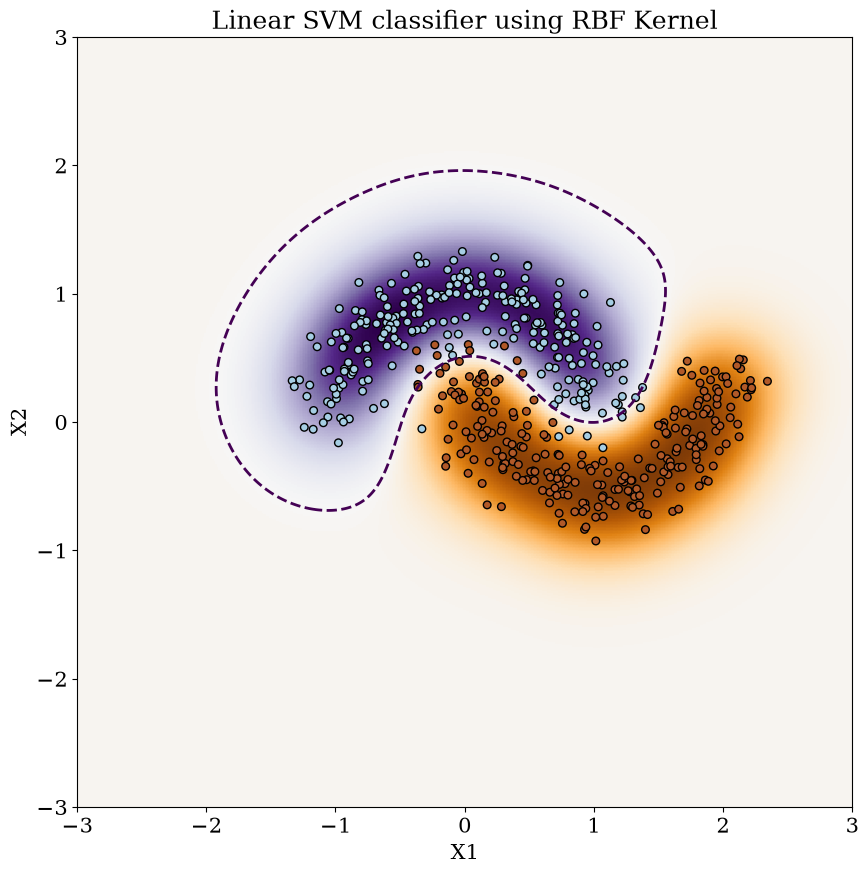

In [36]:
xx, yy = np.meshgrid(np.linspace(-3, 3, 500), np.linspace(-3, 3, 500))
np.random.seed(0)


Z_rbf = clf_rbf.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z_rbf = Z_rbf.reshape(xx.shape)

plt.figure(figsize=(10,10))
plt.imshow(
    Z_rbf,
    interpolation="nearest",
    extent=(xx.min(), xx.max(), yy.min(), yy.max()),
    aspect="auto",
    origin="lower",
    cmap=plt.cm.PuOr_r,
)
contours = plt.contour(xx, yy, Z_rbf, levels=[0], linewidths=2, linestyles="dashed")
plt.scatter(X[:, 0], X[:, 1], s=30, c=y, cmap=plt.cm.Paired, edgecolors="k")
plt.axis([-3, 3, -3, 3])
plt.title('Linear SVM classifier using RBF Kernel')
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()


# Plot the decision function for Sigmoid kernel

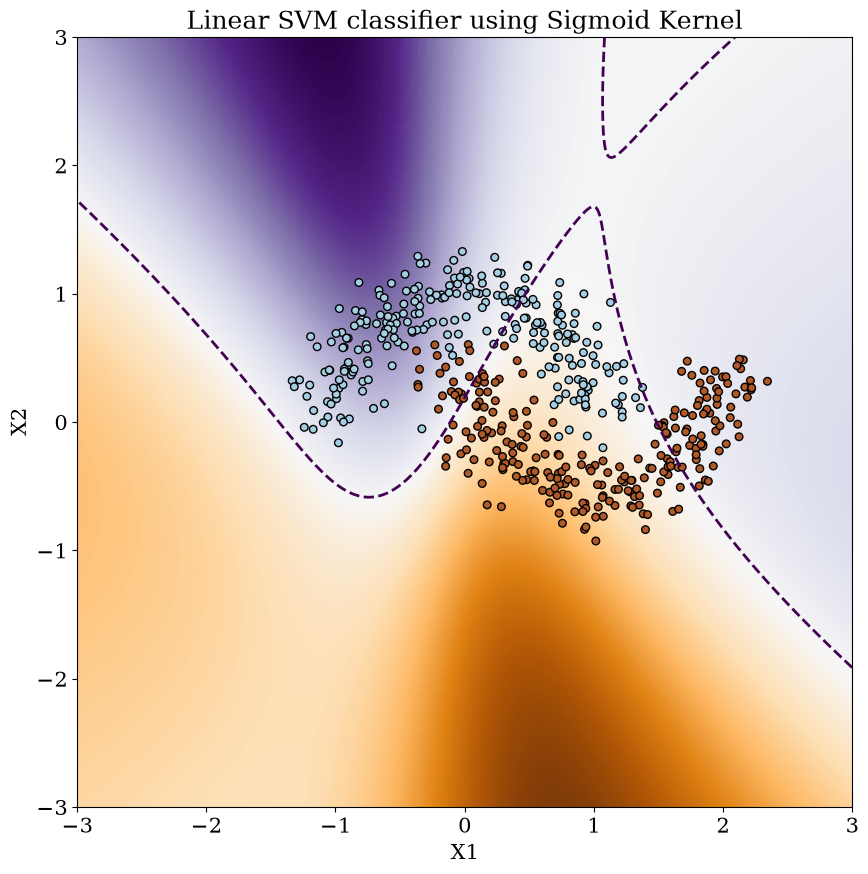

In [37]:
xx, yy = np.meshgrid(np.linspace(-3, 3, 500), np.linspace(-3, 3, 500))
np.random.seed(0)


Z_s = clf_sigmoid.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z_s = Z_s.reshape(xx.shape)

plt.figure(figsize=(10,10))
plt.imshow(
    Z_s,
    interpolation="nearest",
    extent=(xx.min(), xx.max(), yy.min(), yy.max()),
    aspect="auto",
    origin="lower",
    cmap=plt.cm.PuOr_r,
)
contours = plt.contour(xx, yy, Z_s, levels=[0], linewidths=2, linestyles="dashed")
plt.scatter(X[:, 0], X[:, 1], s=30, c=y, cmap=plt.cm.Paired, edgecolors="k")
plt.axis([-3, 3, -3, 3])
plt.title('Linear SVM classifier using Sigmoid Kernel')
plt.xlabel('X1')
plt.ylabel('X2')
plt.show()


# 5. Modulation Classification (from Communication Systems)

PART 1: MODULATION TECHNIQUES VISUALIZATION


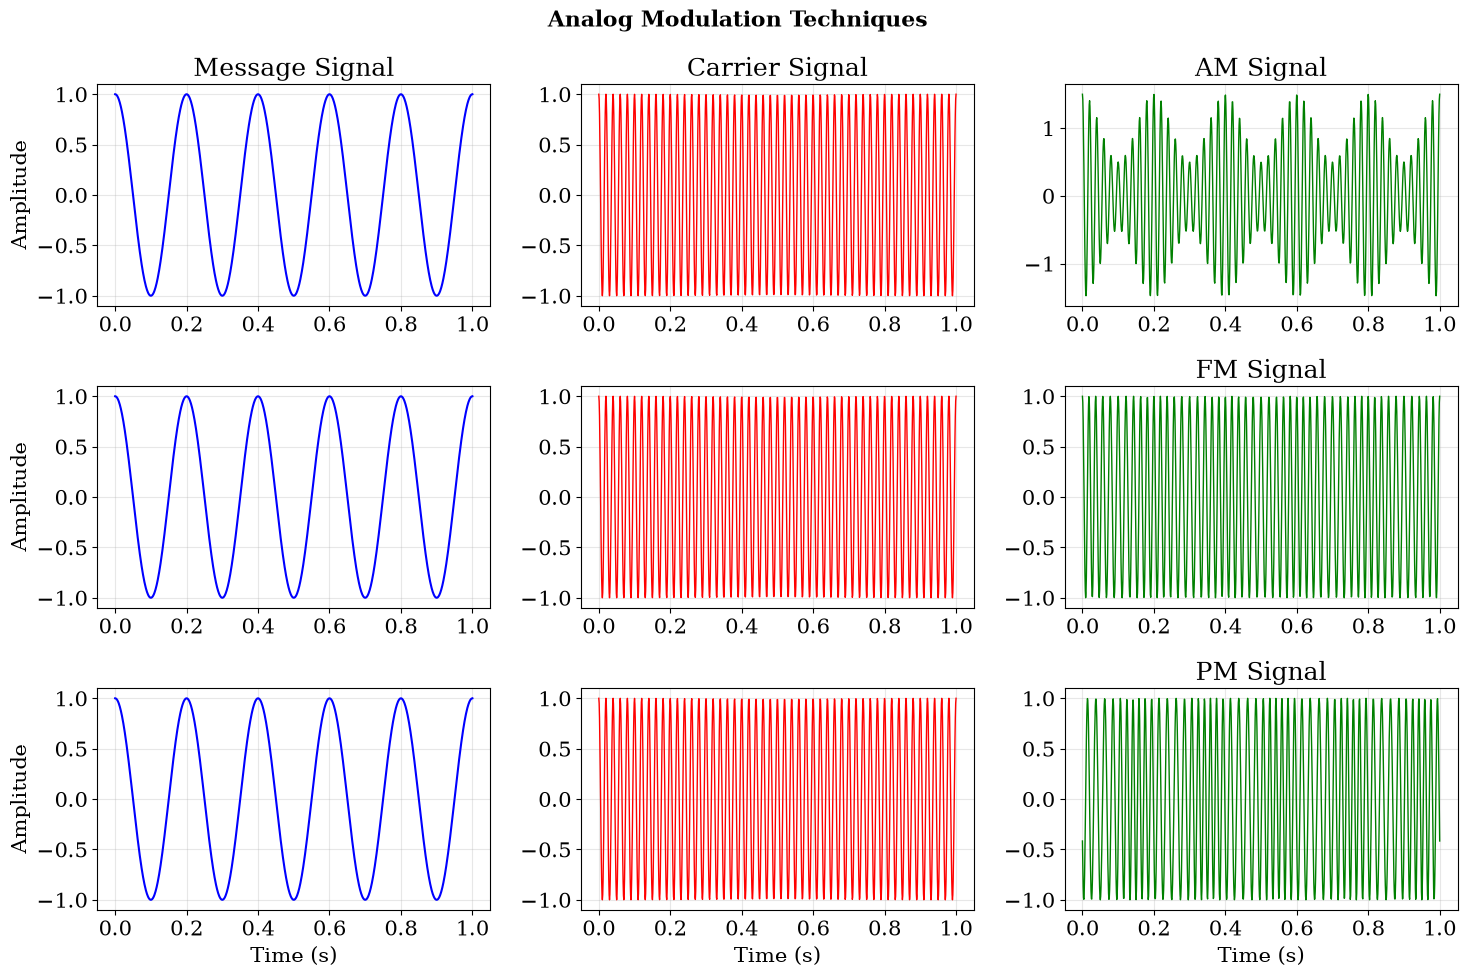

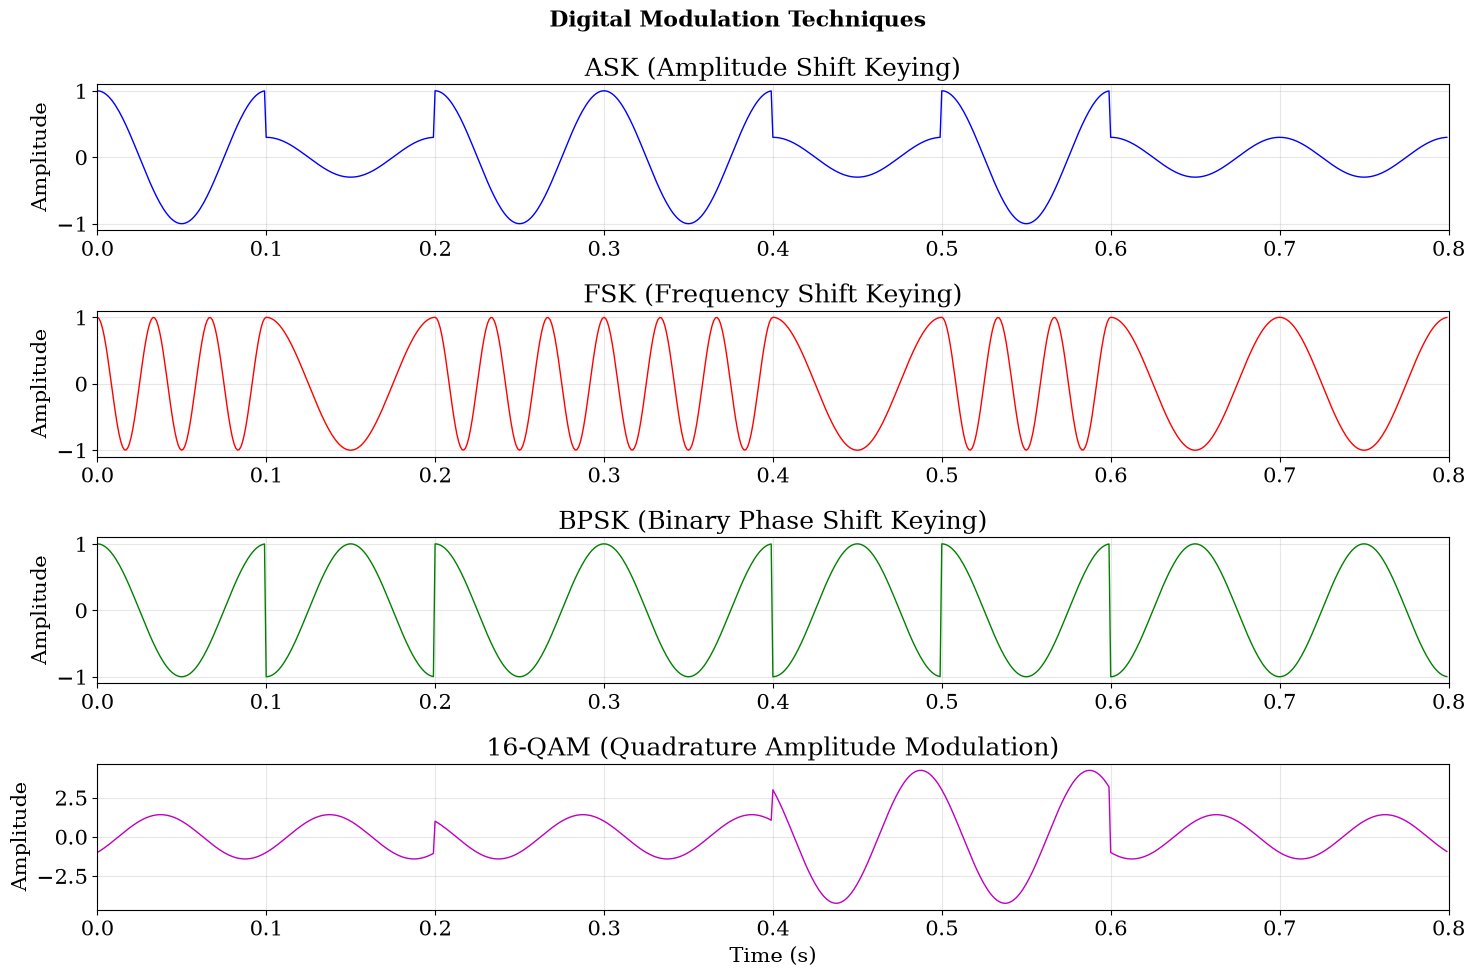


PART 2: SVM-BASED MODULATION CLASSIFICATION

Generating dataset...
Training SVM classifier...

Classification Accuracy: 53.89%

Classification Report:
              precision    recall  f1-score   support

          AM       1.00      1.00      1.00        55
          FM       0.31      0.42      0.36        59
          PM       0.33      0.45      0.38        64
         ASK       1.00      1.00      1.00        65
         FSK       0.26      0.13      0.18        67
        BPSK       0.28      0.22      0.25        50

    accuracy                           0.54       360
   macro avg       0.53      0.54      0.53       360
weighted avg       0.53      0.54      0.53       360



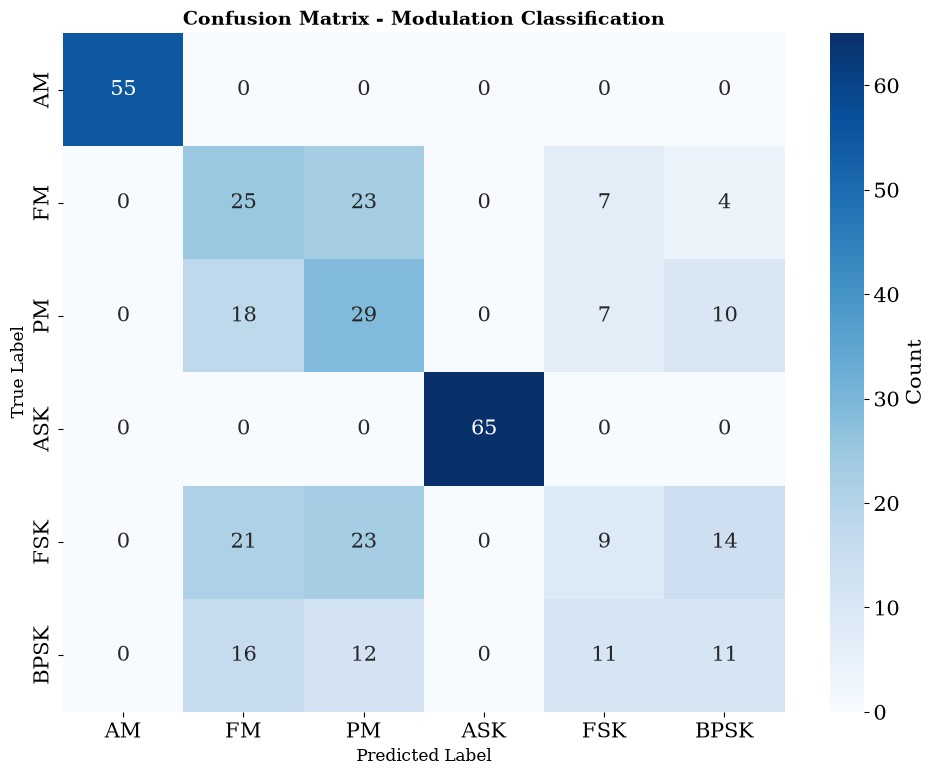

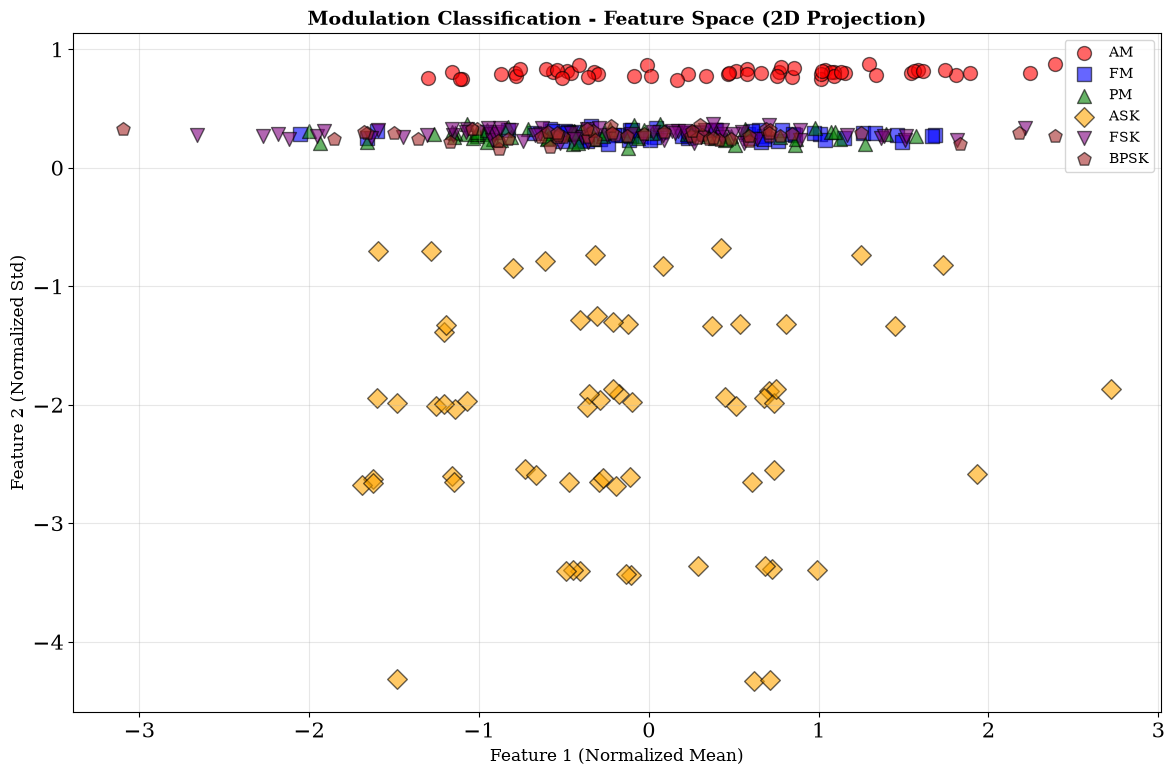

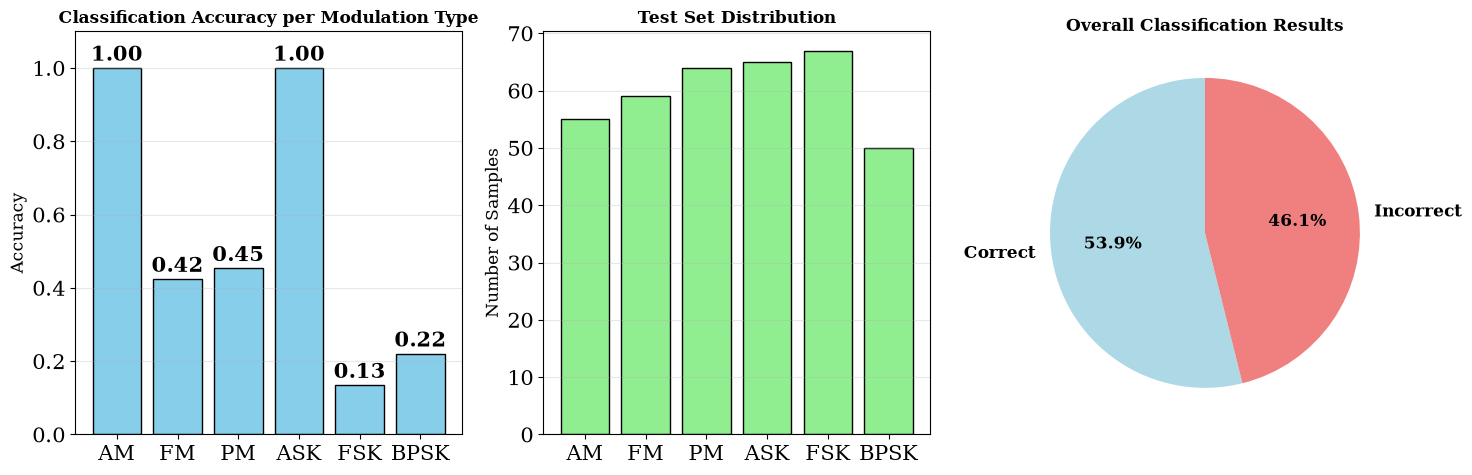


- Total samples: 1200
- Training samples: 840
- Test samples: 360
- Number of features: 10
- Number of modulation types: 6
- Overall accuracy: 53.89%


In [38]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler
import seaborn as sns

# Set random seed for reproducibility
np.random.seed(42)

# ============================================================================
# PART 1: MODULATION TECHNIQUES WITH VISUALIZATION
# ============================================================================

def amplitude_modulation(t, fc, fm, A_c=1, A_m=0.5):
    """
    Amplitude Modulation (AM)
    s(t) = [A_c + A_m * m(t)] * cos(2πfct)
    """
    message = np.cos(2 * np.pi * fm * t)
    carrier = np.cos(2 * np.pi * fc * t)
    am_signal = (A_c + A_m * message) * carrier
    return message, carrier, am_signal

def frequency_modulation(t, fc, fm, kf=5):
    """
    Frequency Modulation (FM)
    s(t) = cos(2πfct + kf∫m(τ)dτ)
    """
    message = np.cos(2 * np.pi * fm * t)
    carrier = np.cos(2 * np.pi * fc * t)
    # Integral of message signal
    integral_m = (1/(2*np.pi*fm)) * np.sin(2 * np.pi * fm * t)
    fm_signal = np.cos(2 * np.pi * fc * t + 2 * np.pi * kf * integral_m)
    return message, carrier, fm_signal

def phase_modulation(t, fc, fm, kp=2):
    """
    Phase Modulation (PM)
    s(t) = cos(2πfct + kp*m(t))
    """
    message = np.cos(2 * np.pi * fm * t)
    carrier = np.cos(2 * np.pi * fc * t)
    pm_signal = np.cos(2 * np.pi * fc * t + kp * message)
    return message, carrier, pm_signal

def ask_modulation(bits, fc, fs, samples_per_bit):
    """
    Amplitude Shift Keying (ASK)
    Binary digital modulation
    """
    t = np.arange(0, len(bits) * samples_per_bit) / fs
    ask_signal = np.zeros(len(t))
    
    for i, bit in enumerate(bits):
        start = i * samples_per_bit
        end = (i + 1) * samples_per_bit
        if bit == 1:
            ask_signal[start:end] = np.cos(2 * np.pi * fc * t[start:end])
        else:
            ask_signal[start:end] = 0.3 * np.cos(2 * np.pi * fc * t[start:end])
    
    return t, ask_signal, bits

def fsk_modulation(bits, f1, f2, fs, samples_per_bit):
    """
    Frequency Shift Keying (FSK)
    Binary digital modulation
    """
    t = np.arange(0, len(bits) * samples_per_bit) / fs
    fsk_signal = np.zeros(len(t))
    
    for i, bit in enumerate(bits):
        start = i * samples_per_bit
        end = (i + 1) * samples_per_bit
        if bit == 1:
            fsk_signal[start:end] = np.cos(2 * np.pi * f2 * t[start:end])
        else:
            fsk_signal[start:end] = np.cos(2 * np.pi * f1 * t[start:end])
    
    return t, fsk_signal, bits

def psk_modulation(bits, fc, fs, samples_per_bit):
    """
    Phase Shift Keying (PSK)
    Binary digital modulation (BPSK)
    """
    t = np.arange(0, len(bits) * samples_per_bit) / fs
    psk_signal = np.zeros(len(t))
    
    for i, bit in enumerate(bits):
        start = i * samples_per_bit
        end = (i + 1) * samples_per_bit
        if bit == 1:
            psk_signal[start:end] = np.cos(2 * np.pi * fc * t[start:end])
        else:
            psk_signal[start:end] = np.cos(2 * np.pi * fc * t[start:end] + np.pi)
    
    return t, psk_signal, bits

def qam_modulation(symbols, fc, fs, samples_per_symbol):
    """
    Quadrature Amplitude Modulation (QAM)
    16-QAM example
    """
    # 16-QAM constellation points
    constellation = {
        0: (-3, -3), 1: (-3, -1), 2: (-3, 1), 3: (-3, 3),
        4: (-1, -3), 5: (-1, -1), 6: (-1, 1), 7: (-1, 3),
        8: (1, -3), 9: (1, -1), 10: (1, 1), 11: (1, 3),
        12: (3, -3), 13: (3, -1), 14: (3, 1), 15: (3, 3)
    }
    
    t = np.arange(0, len(symbols) * samples_per_symbol) / fs
    qam_signal = np.zeros(len(t))
    
    for i, symbol in enumerate(symbols):
        start = i * samples_per_symbol
        end = (i + 1) * samples_per_symbol
        I, Q = constellation[symbol]
        qam_signal[start:end] = (I * np.cos(2 * np.pi * fc * t[start:end]) - 
                                  Q * np.sin(2 * np.pi * fc * t[start:end]))
    
    return t, qam_signal, symbols

# Visualize analog modulation techniques
print("="*60)
print("PART 1: MODULATION TECHNIQUES VISUALIZATION")
print("="*60)

# Parameters for analog modulation
fc = 50  # Carrier frequency
fm = 5   # Message frequency
t = np.linspace(0, 1, 1000)

# Generate modulated signals
msg_am, carr_am, am_sig = amplitude_modulation(t, fc, fm)
msg_fm, carr_fm, fm_sig = frequency_modulation(t, fc, fm)
msg_pm, carr_pm, pm_sig = phase_modulation(t, fc, fm)

# Plot analog modulation
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
fig.suptitle('Analog Modulation Techniques', fontsize=16, fontweight='bold')

# AM
axes[0, 0].plot(t, msg_am, 'b', linewidth=1.5)
axes[0, 0].set_title('Message Signal')
axes[0, 0].set_ylabel('Amplitude')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(t, carr_am, 'r', linewidth=1)
axes[0, 1].set_title('Carrier Signal')
axes[0, 1].grid(True, alpha=0.3)

axes[0, 2].plot(t, am_sig, 'g', linewidth=1)
axes[0, 2].set_title('AM Signal')
axes[0, 2].grid(True, alpha=0.3)

# FM
axes[1, 0].plot(t, msg_fm, 'b', linewidth=1.5)
axes[1, 0].set_ylabel('Amplitude')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(t, carr_fm, 'r', linewidth=1)
axes[1, 1].grid(True, alpha=0.3)

axes[1, 2].plot(t, fm_sig, 'g', linewidth=1)
axes[1, 2].set_title('FM Signal')
axes[1, 2].grid(True, alpha=0.3)

# PM
axes[2, 0].plot(t, msg_pm, 'b', linewidth=1.5)
axes[2, 0].set_xlabel('Time (s)')
axes[2, 0].set_ylabel('Amplitude')
axes[2, 0].grid(True, alpha=0.3)

axes[2, 1].plot(t, carr_pm, 'r', linewidth=1)
axes[2, 1].set_xlabel('Time (s)')
axes[2, 1].grid(True, alpha=0.3)

axes[2, 2].plot(t, pm_sig, 'g', linewidth=1)
axes[2, 2].set_title('PM Signal')
axes[2, 2].set_xlabel('Time (s)')
axes[2, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Visualize digital modulation techniques
bits = np.array([1, 0, 1, 1, 0, 1, 0, 0])
symbols = np.array([5, 10, 15, 6])  # 16-QAM symbols
fs = 1000
samples_per_bit = 100

t_ask, ask_sig, _ = ask_modulation(bits, fc=10, fs=fs, samples_per_bit=samples_per_bit)
t_fsk, fsk_sig, _ = fsk_modulation(bits, f1=10, f2=30, fs=fs, samples_per_bit=samples_per_bit)
t_psk, psk_sig, _ = psk_modulation(bits, fc=10, fs=fs, samples_per_bit=samples_per_bit)
t_qam, qam_sig, _ = qam_modulation(symbols, fc=10, fs=fs, samples_per_symbol=200)

# Plot digital modulation
fig, axes = plt.subplots(4, 1, figsize=(15, 10))
fig.suptitle('Digital Modulation Techniques', fontsize=16, fontweight='bold')

axes[0].plot(t_ask, ask_sig, 'b', linewidth=1)
axes[0].set_title('ASK (Amplitude Shift Keying)')
axes[0].set_ylabel('Amplitude')
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim([0, len(bits) * samples_per_bit / fs])

axes[1].plot(t_fsk, fsk_sig, 'r', linewidth=1)
axes[1].set_title('FSK (Frequency Shift Keying)')
axes[1].set_ylabel('Amplitude')
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim([0, len(bits) * samples_per_bit / fs])

axes[2].plot(t_psk, psk_sig, 'g', linewidth=1)
axes[2].set_title('BPSK (Binary Phase Shift Keying)')
axes[2].set_ylabel('Amplitude')
axes[2].grid(True, alpha=0.3)
axes[2].set_xlim([0, len(bits) * samples_per_bit / fs])

axes[3].plot(t_qam, qam_sig, 'm', linewidth=1)
axes[3].set_title('16-QAM (Quadrature Amplitude Modulation)')
axes[3].set_xlabel('Time (s)')
axes[3].set_ylabel('Amplitude')
axes[3].grid(True, alpha=0.3)
axes[3].set_xlim([0, len(symbols) * 200 / fs])

plt.tight_layout()
plt.show()

# ============================================================================
# PART 2: FEATURE EXTRACTION FOR MODULATION CLASSIFICATION
# ============================================================================

def extract_features(signal):
    """
    Extract features from modulated signal for classification
    Features: mean, std, max, min, variance, kurtosis, skewness
    """
    features = []
    
    # Statistical features
    features.append(np.mean(signal))
    features.append(np.std(signal))
    features.append(np.max(signal))
    features.append(np.min(signal))
    features.append(np.var(signal))
    
    # Higher order statistics
    from scipy import stats
    features.append(stats.kurtosis(signal))
    features.append(stats.skew(signal))
    
    # Instantaneous amplitude
    analytic_signal = np.abs(signal)
    features.append(np.mean(analytic_signal))
    features.append(np.std(analytic_signal))
    features.append(np.max(analytic_signal) - np.min(analytic_signal))
    
    return features

def generate_dataset(n_samples=200, noise_level=0.1):
    """
    Generate dataset with different modulation types
    """
    X = []
    y = []
    
    fc = 50
    fm = 5
    fs = 1000
    samples_per_bit = 100
    t = np.linspace(0, 1, 1000)
    
    for _ in range(n_samples):
        # Generate different modulation types
        
        # AM
        _, _, am_sig = amplitude_modulation(t, fc, fm)
        am_sig += noise_level * np.random.randn(len(am_sig))
        X.append(extract_features(am_sig))
        y.append(0)
        
        # FM
        _, _, fm_sig = frequency_modulation(t, fc, fm)
        fm_sig += noise_level * np.random.randn(len(fm_sig))
        X.append(extract_features(fm_sig))
        y.append(1)
        
        # PM
        _, _, pm_sig = phase_modulation(t, fc, fm)
        pm_sig += noise_level * np.random.randn(len(pm_sig))
        X.append(extract_features(pm_sig))
        y.append(2)
        
        # ASK
        bits = np.random.randint(0, 2, 8)
        _, ask_sig, _ = ask_modulation(bits, fc=10, fs=fs, samples_per_bit=samples_per_bit)
        ask_sig += noise_level * np.random.randn(len(ask_sig))
        X.append(extract_features(ask_sig))
        y.append(3)
        
        # FSK
        bits = np.random.randint(0, 2, 8)
        _, fsk_sig, _ = fsk_modulation(bits, f1=10, f2=30, fs=fs, samples_per_bit=samples_per_bit)
        fsk_sig += noise_level * np.random.randn(len(fsk_sig))
        X.append(extract_features(fsk_sig))
        y.append(4)
        
        # PSK
        bits = np.random.randint(0, 2, 8)
        _, psk_sig, _ = psk_modulation(bits, fc=10, fs=fs, samples_per_bit=samples_per_bit)
        psk_sig += noise_level * np.random.randn(len(psk_sig))
        X.append(extract_features(psk_sig))
        y.append(5)
    
    return np.array(X), np.array(y)

# ============================================================================
# PART 3: SVM-BASED MODULATION CLASSIFICATION
# ============================================================================

print("\n" + "="*60)
print("PART 2: SVM-BASED MODULATION CLASSIFICATION")
print("="*60)

# Generate dataset
print("\nGenerating dataset...")
X, y = generate_dataset(n_samples=200, noise_level=0.1)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train SVM classifier
print("Training SVM classifier...")
svm_classifier = SVC(kernel='rbf', C=10, gamma='scale', random_state=42)
svm_classifier.fit(X_train_scaled, y_train)

# Make predictions
y_pred = svm_classifier.predict(X_test_scaled)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"\nClassification Accuracy: {accuracy*100:.2f}%")

# Class labels
class_names = ['AM', 'FM', 'PM', 'ASK', 'FSK', 'BPSK']

# Classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

# ============================================================================
# PART 4: VISUALIZATION OF CLASSIFICATION RESULTS
# ============================================================================

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names,
            cbar_kws={'label': 'Count'})
plt.title('Confusion Matrix - Modulation Classification', fontsize=14, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()

# Feature importance visualization (using first 2 features for 2D plot)
plt.figure(figsize=(12, 8))
colors = ['red', 'blue', 'green', 'orange', 'purple', 'brown']
markers = ['o', 's', '^', 'D', 'v', 'p']

for i, class_name in enumerate(class_names):
    mask = y_test == i
    plt.scatter(X_test_scaled[mask, 0], X_test_scaled[mask, 1], 
                c=colors[i], marker=markers[i], label=class_name, 
                s=100, alpha=0.6, edgecolors='black')

plt.xlabel('Feature 1 (Normalized Mean)', fontsize=12)
plt.ylabel('Feature 2 (Normalized Std)', fontsize=12)
plt.title('Modulation Classification - Feature Space (2D Projection)', 
          fontsize=14, fontweight='bold')
plt.legend(loc='best', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Performance metrics by class
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Accuracy per class
accuracy_per_class = cm.diagonal() / cm.sum(axis=1)
axes[0].bar(class_names, accuracy_per_class, color='skyblue', edgecolor='black')
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].set_title('Classification Accuracy per Modulation Type', fontsize=12, fontweight='bold')
axes[0].set_ylim([0, 1.1])
axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(accuracy_per_class):
    axes[0].text(i, v + 0.02, f'{v:.2f}', ha='center', fontweight='bold')

# Sample distribution
unique, counts = np.unique(y_test, return_counts=True)
axes[1].bar([class_names[i] for i in unique], counts, color='lightgreen', edgecolor='black')
axes[1].set_ylabel('Number of Samples', fontsize=12)
axes[1].set_title('Test Set Distribution', fontsize=12, fontweight='bold')
axes[1].grid(axis='y', alpha=0.3)

# Correct vs Incorrect predictions
correct = np.sum(y_test == y_pred)
incorrect = len(y_test) - correct
axes[2].pie([correct, incorrect], labels=['Correct', 'Incorrect'], 
            autopct='%1.1f%%', colors=['lightblue', 'lightcoral'],
            startangle=90, textprops={'fontsize': 12, 'fontweight': 'bold'})
axes[2].set_title('Overall Classification Results', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("="*60)
print(f"- Total samples: {len(y)}")
print(f"- Training samples: {len(y_train)}")
print(f"- Test samples: {len(y_test)}")
print(f"- Number of features: {X.shape[1]}")
print(f"- Number of modulation types: {len(class_names)}")
print(f"- Overall accuracy: {accuracy*100:.2f}%")

## More rigorous features for Modulation Classification

ADVANCED SVM-BASED MODULATION CLASSIFICATION


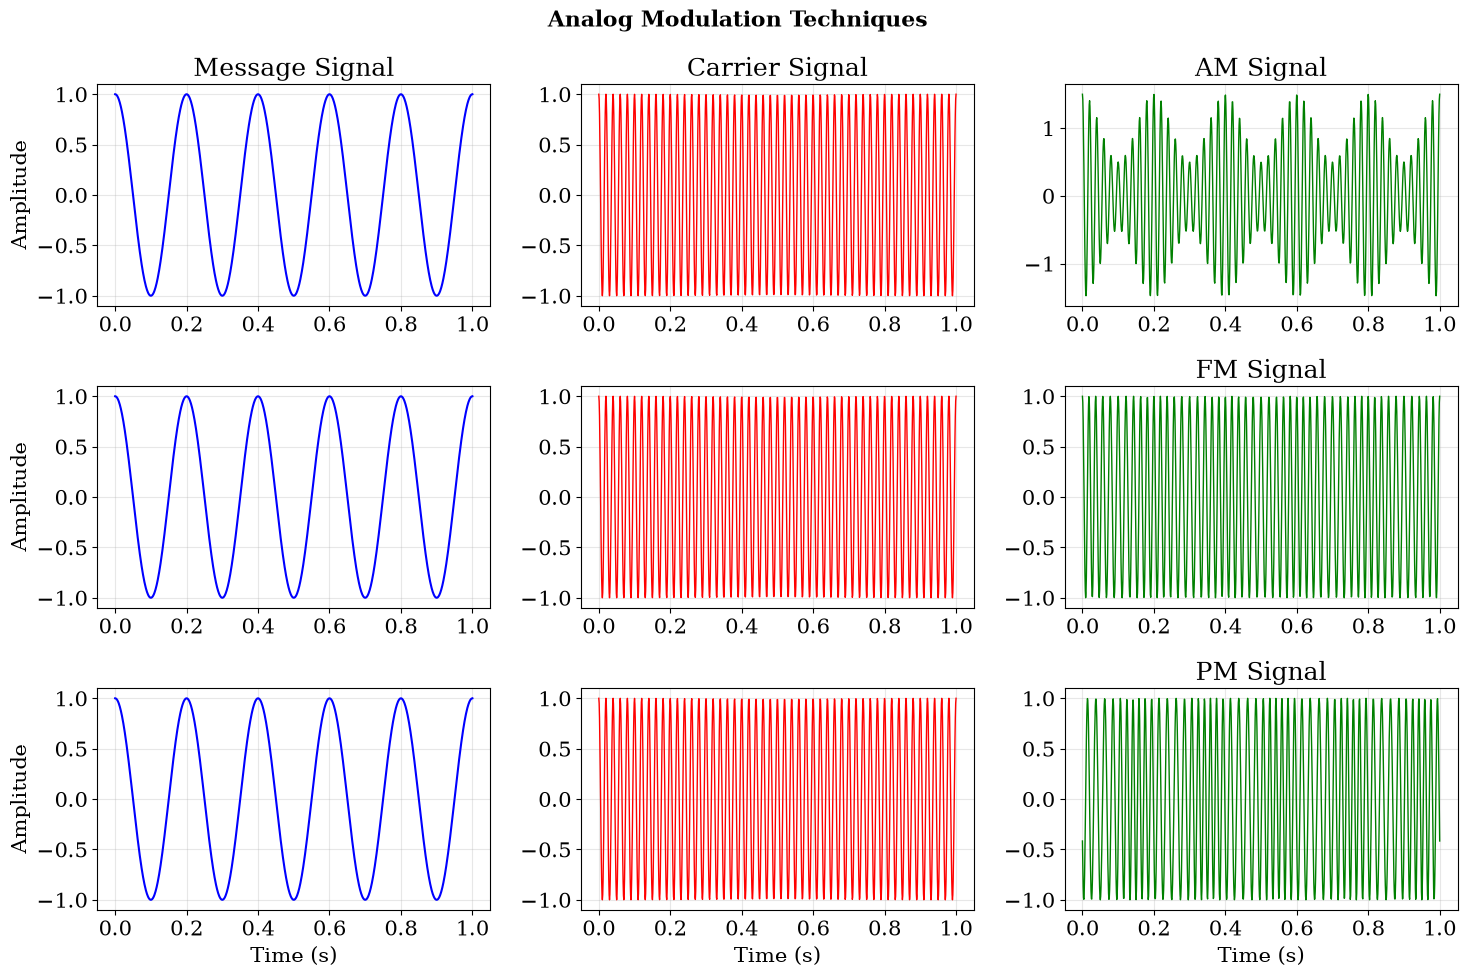


APPLYING ADVANCED SVM TECHNIQUES

1. Generating enhanced dataset with more features...
   Dataset shape: (1800, 22)
   Number of features: 22

2. TECHNIQUE 1: Hyperparameter Tuning with GridSearchCV
   Searching for optimal C, gamma, and kernel parameters...
   Best parameters: {'C': 100, 'gamma': 0.01, 'kernel': 'sigmoid'}
   Best cross-validation score: 97.04%
   Test accuracy: 97.56%

3. TECHNIQUE 2: Dimensionality Reduction with PCA
   PCA with 10 components: 96.89% accuracy (99.3% variance)
   PCA with 15 components: 97.56% accuracy (99.9% variance)
   PCA with 20 components: 97.56% accuracy (100.0% variance)
   Selected: 15 components with 97.56% accuracy

4. TECHNIQUE 3: Ensemble of SVMs (Voting Classifier)


/home/rudraksh/cpe486586pkg/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/rudraksh/cpe486586pkg/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/rudraksh/cpe486586pkg/.venv/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


   Ensemble accuracy: 97.78%

5. TECHNIQUE 4: Class Weight Balancing
   Balanced SVM accuracy: 97.56%

6. TECHNIQUE 5: One-vs-One Multi-class Strategy
   One-vs-One SVM accuracy: 97.56%

ACCURACY COMPARISON OF ALL TECHNIQUES
Basic SVM..................... 94.22%
Hyperparameter Tuning......... 97.56%
PCA + SVM..................... 97.56%
Ensemble (Voting)............. 97.78%
Balanced Classes.............. 97.56%
One-vs-One.................... 97.56%

Best technique: Ensemble (Voting) with 97.78% accuracy


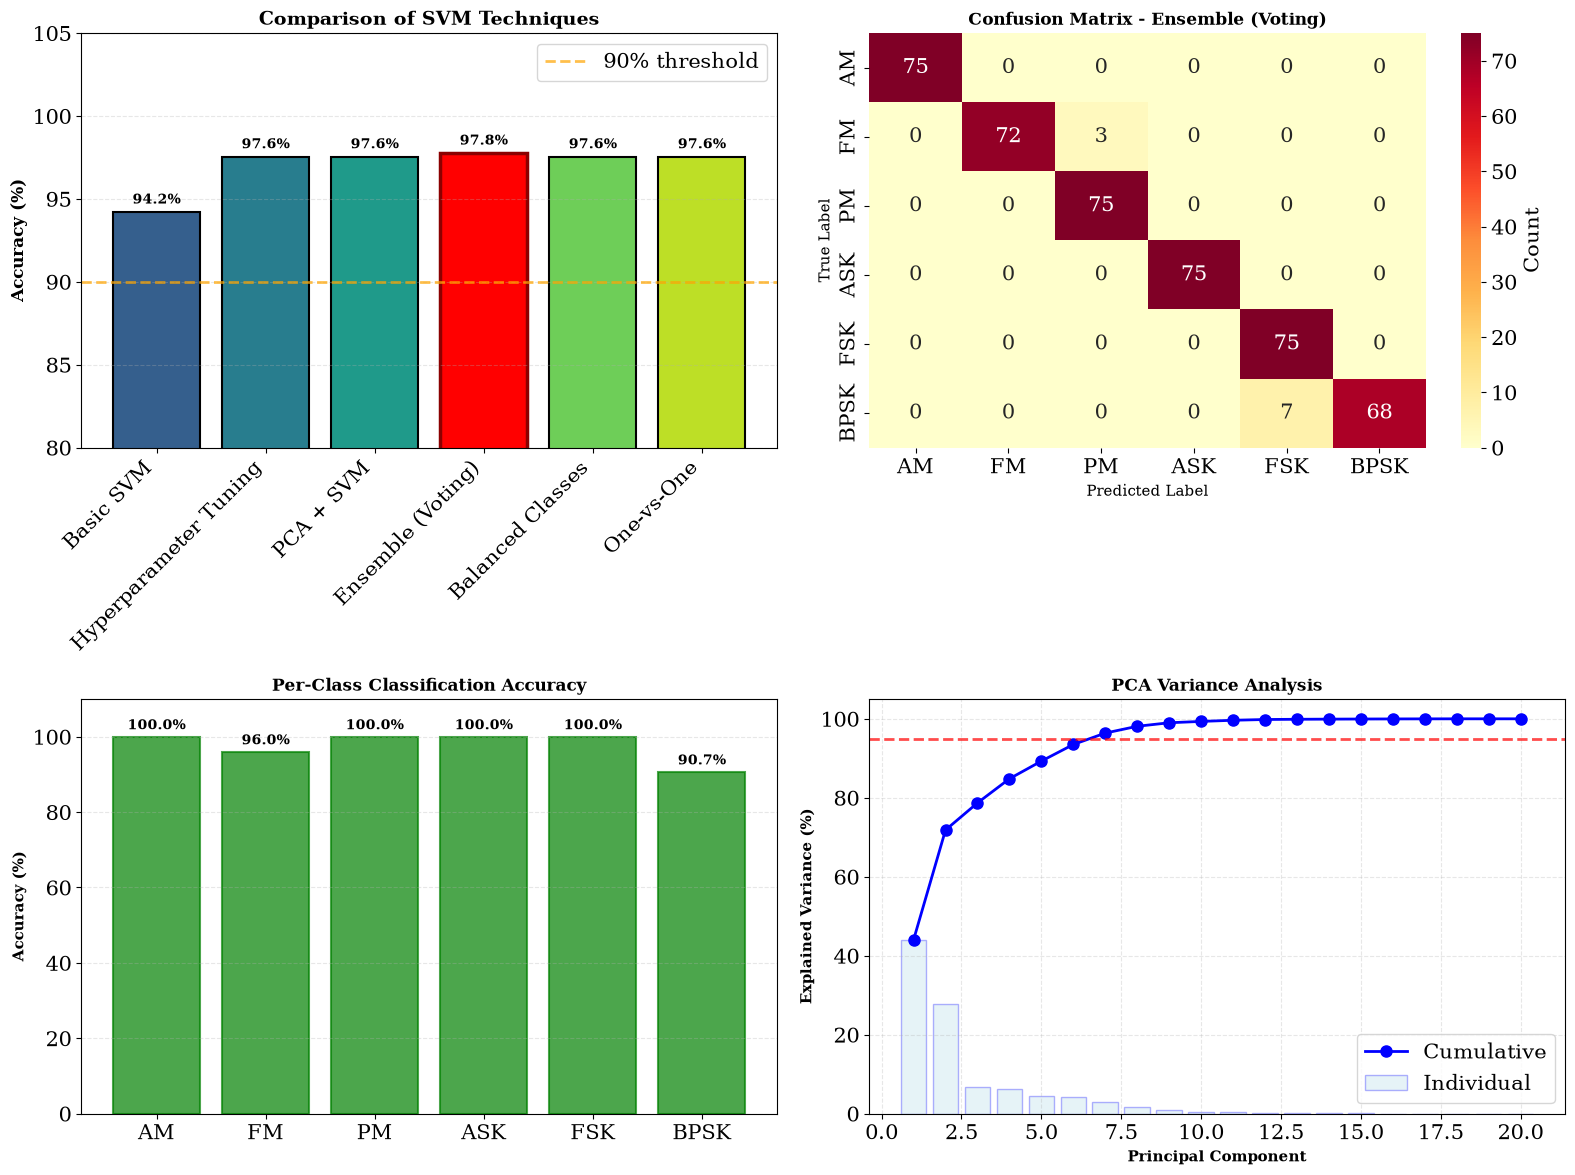


DETAILED CLASSIFICATION REPORT - Ensemble (Voting)
              precision    recall  f1-score   support

          AM       1.00      1.00      1.00        75
          FM       1.00      0.96      0.98        75
          PM       0.96      1.00      0.98        75
         ASK       1.00      1.00      1.00        75
         FSK       0.91      1.00      0.96        75
        BPSK       1.00      0.91      0.95        75

    accuracy                           0.98       450
   macro avg       0.98      0.98      0.98       450
weighted avg       0.98      0.98      0.98       450


SUMMARY
Total samples: 1800
Training samples: 1350
Test samples: 450
Original features: 22
Modulation types: 6

Basic SVM accuracy: 94.22%
Best technique: Ensemble (Voting)
Best accuracy: 97.78%
Improvement: 3.56%


In [39]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import VotingClassifier
from sklearn.decomposition import PCA
import seaborn as sns
from itertools import product

# Set random seed for reproducibility
np.random.seed(42)

# ============================================================================
# PART 1: MODULATION TECHNIQUES WITH VISUALIZATION
# ============================================================================

def amplitude_modulation(t, fc, fm, A_c=1, A_m=0.5):
    """Amplitude Modulation (AM)"""
    message = np.cos(2 * np.pi * fm * t)
    carrier = np.cos(2 * np.pi * fc * t)
    am_signal = (A_c + A_m * message) * carrier
    return message, carrier, am_signal

def frequency_modulation(t, fc, fm, kf=5):
    """Frequency Modulation (FM)"""
    message = np.cos(2 * np.pi * fm * t)
    carrier = np.cos(2 * np.pi * fc * t)
    integral_m = (1/(2*np.pi*fm)) * np.sin(2 * np.pi * fm * t)
    fm_signal = np.cos(2 * np.pi * fc * t + 2 * np.pi * kf * integral_m)
    return message, carrier, fm_signal

def phase_modulation(t, fc, fm, kp=2):
    """Phase Modulation (PM)"""
    message = np.cos(2 * np.pi * fm * t)
    carrier = np.cos(2 * np.pi * fc * t)
    pm_signal = np.cos(2 * np.pi * fc * t + kp * message)
    return message, carrier, pm_signal

def ask_modulation(bits, fc, fs, samples_per_bit):
    """Amplitude Shift Keying (ASK)"""
    t = np.arange(0, len(bits) * samples_per_bit) / fs
    ask_signal = np.zeros(len(t))
    
    for i, bit in enumerate(bits):
        start = i * samples_per_bit
        end = (i + 1) * samples_per_bit
        if bit == 1:
            ask_signal[start:end] = np.cos(2 * np.pi * fc * t[start:end])
        else:
            ask_signal[start:end] = 0.3 * np.cos(2 * np.pi * fc * t[start:end])
    
    return t, ask_signal, bits

def fsk_modulation(bits, f1, f2, fs, samples_per_bit):
    """Frequency Shift Keying (FSK)"""
    t = np.arange(0, len(bits) * samples_per_bit) / fs
    fsk_signal = np.zeros(len(t))
    
    for i, bit in enumerate(bits):
        start = i * samples_per_bit
        end = (i + 1) * samples_per_bit
        if bit == 1:
            fsk_signal[start:end] = np.cos(2 * np.pi * f2 * t[start:end])
        else:
            fsk_signal[start:end] = np.cos(2 * np.pi * f1 * t[start:end])
    
    return t, fsk_signal, bits

def psk_modulation(bits, fc, fs, samples_per_bit):
    """Phase Shift Keying (PSK)"""
    t = np.arange(0, len(bits) * samples_per_bit) / fs
    psk_signal = np.zeros(len(t))
    
    for i, bit in enumerate(bits):
        start = i * samples_per_bit
        end = (i + 1) * samples_per_bit
        if bit == 1:
            psk_signal[start:end] = np.cos(2 * np.pi * fc * t[start:end])
        else:
            psk_signal[start:end] = np.cos(2 * np.pi * fc * t[start:end] + np.pi)
    
    return t, psk_signal, bits

def qam_modulation(symbols, fc, fs, samples_per_symbol):
    """Quadrature Amplitude Modulation (QAM)"""
    constellation = {
        0: (-3, -3), 1: (-3, -1), 2: (-3, 1), 3: (-3, 3),
        4: (-1, -3), 5: (-1, -1), 6: (-1, 1), 7: (-1, 3),
        8: (1, -3), 9: (1, -1), 10: (1, 1), 11: (1, 3),
        12: (3, -3), 13: (3, -1), 14: (3, 1), 15: (3, 3)
    }
    
    t = np.arange(0, len(symbols) * samples_per_symbol) / fs
    qam_signal = np.zeros(len(t))
    
    for i, symbol in enumerate(symbols):
        start = i * samples_per_symbol
        end = (i + 1) * samples_per_symbol
        I, Q = constellation[symbol]
        qam_signal[start:end] = (I * np.cos(2 * np.pi * fc * t[start:end]) - 
                                  Q * np.sin(2 * np.pi * fc * t[start:end]))
    
    return t, qam_signal, symbols

# Visualize analog modulation techniques
print("="*70)
print("ADVANCED SVM-BASED MODULATION CLASSIFICATION")
print("="*70)

# Parameters for analog modulation
fc = 50
fm = 5
t = np.linspace(0, 1, 1000)

# Generate modulated signals
msg_am, carr_am, am_sig = amplitude_modulation(t, fc, fm)
msg_fm, carr_fm, fm_sig = frequency_modulation(t, fc, fm)
msg_pm, carr_pm, pm_sig = phase_modulation(t, fc, fm)

# Plot analog modulation
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
fig.suptitle('Analog Modulation Techniques', fontsize=16, fontweight='bold')

# AM
axes[0, 0].plot(t, msg_am, 'b', linewidth=1.5)
axes[0, 0].set_title('Message Signal')
axes[0, 0].set_ylabel('Amplitude')
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].plot(t, carr_am, 'r', linewidth=1)
axes[0, 1].set_title('Carrier Signal')
axes[0, 1].grid(True, alpha=0.3)

axes[0, 2].plot(t, am_sig, 'g', linewidth=1)
axes[0, 2].set_title('AM Signal')
axes[0, 2].grid(True, alpha=0.3)

# FM
axes[1, 0].plot(t, msg_fm, 'b', linewidth=1.5)
axes[1, 0].set_ylabel('Amplitude')
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].plot(t, carr_fm, 'r', linewidth=1)
axes[1, 1].grid(True, alpha=0.3)

axes[1, 2].plot(t, fm_sig, 'g', linewidth=1)
axes[1, 2].set_title('FM Signal')
axes[1, 2].grid(True, alpha=0.3)

# PM
axes[2, 0].plot(t, msg_pm, 'b', linewidth=1.5)
axes[2, 0].set_xlabel('Time (s)')
axes[2, 0].set_ylabel('Amplitude')
axes[2, 0].grid(True, alpha=0.3)

axes[2, 1].plot(t, carr_pm, 'r', linewidth=1)
axes[2, 1].set_xlabel('Time (s)')
axes[2, 1].grid(True, alpha=0.3)

axes[2, 2].plot(t, pm_sig, 'g', linewidth=1)
axes[2, 2].set_title('PM Signal')
axes[2, 2].set_xlabel('Time (s)')
axes[2, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================================
# PART 2: ENHANCED FEATURE EXTRACTION
# ============================================================================

def extract_enhanced_features(signal):
    """
    Extract enhanced features for better classification
    Includes temporal, spectral, and statistical features
    """
    features = []
    from scipy import stats
    
    # 1. Temporal statistics
    features.append(np.mean(signal))
    features.append(np.std(signal))
    features.append(np.max(signal))
    features.append(np.min(signal))
    features.append(np.var(signal))
    features.append(np.median(signal))
    features.append(np.percentile(signal, 25))
    features.append(np.percentile(signal, 75))
    
    # 2. Higher order statistics
    features.append(stats.kurtosis(signal))
    features.append(stats.skew(signal))
    
    # 3. Instantaneous amplitude features
    analytic_signal = np.abs(signal)
    features.append(np.mean(analytic_signal))
    features.append(np.std(analytic_signal))
    features.append(np.max(analytic_signal) - np.min(analytic_signal))
    features.append(np.var(analytic_signal))
    
    # 4. Zero crossing rate
    zero_crossings = np.sum(np.diff(np.sign(signal)) != 0)
    features.append(zero_crossings)
    
    # 5. Signal energy
    features.append(np.sum(signal**2))
    features.append(np.sqrt(np.mean(signal**2)))  # RMS
    
    # 6. Spectral features (FFT-based)
    fft = np.fft.fft(signal)
    magnitude = np.abs(fft)
    features.append(np.mean(magnitude))
    features.append(np.std(magnitude))
    features.append(np.max(magnitude))
    
    # 7. Spectral centroid
    freqs = np.fft.fftfreq(len(signal))
    spectral_centroid = np.sum(freqs * magnitude) / np.sum(magnitude)
    features.append(spectral_centroid)
    
    # 8. Peak-to-average power ratio
    peak_power = np.max(signal**2)
    avg_power = np.mean(signal**2)
    papr = peak_power / (avg_power + 1e-10)
    features.append(papr)
    
    return features

def generate_enhanced_dataset(n_samples=300, noise_level=0.1):
    """Generate dataset with enhanced features"""
    X = []
    y = []
    
    fc = 50
    fm = 5
    fs = 1000
    samples_per_bit = 100
    t = np.linspace(0, 1, 1000)
    
    for _ in range(n_samples):
        # AM
        _, _, am_sig = amplitude_modulation(t, fc, fm, A_m=np.random.uniform(0.3, 0.7))
        am_sig += noise_level * np.random.randn(len(am_sig))
        X.append(extract_enhanced_features(am_sig))
        y.append(0)
        
        # FM
        _, _, fm_sig = frequency_modulation(t, fc, fm, kf=np.random.uniform(3, 7))
        fm_sig += noise_level * np.random.randn(len(fm_sig))
        X.append(extract_enhanced_features(fm_sig))
        y.append(1)
        
        # PM
        _, _, pm_sig = phase_modulation(t, fc, fm, kp=np.random.uniform(1.5, 2.5))
        pm_sig += noise_level * np.random.randn(len(pm_sig))
        X.append(extract_enhanced_features(pm_sig))
        y.append(2)
        
        # ASK
        bits = np.random.randint(0, 2, 8)
        _, ask_sig, _ = ask_modulation(bits, fc=10, fs=fs, samples_per_bit=samples_per_bit)
        ask_sig += noise_level * np.random.randn(len(ask_sig))
        X.append(extract_enhanced_features(ask_sig))
        y.append(3)
        
        # FSK
        bits = np.random.randint(0, 2, 8)
        _, fsk_sig, _ = fsk_modulation(bits, f1=10, f2=30, fs=fs, samples_per_bit=samples_per_bit)
        fsk_sig += noise_level * np.random.randn(len(fsk_sig))
        X.append(extract_enhanced_features(fsk_sig))
        y.append(4)
        
        # PSK
        bits = np.random.randint(0, 2, 8)
        _, psk_sig, _ = psk_modulation(bits, fc=10, fs=fs, samples_per_bit=samples_per_bit)
        psk_sig += noise_level * np.random.randn(len(psk_sig))
        X.append(extract_enhanced_features(psk_sig))
        y.append(5)
    
    return np.array(X), np.array(y)

# ============================================================================
# PART 3: ADVANCED SVM TECHNIQUES FOR BETTER ACCURACY
# ============================================================================

print("\n" + "="*70)
print("APPLYING ADVANCED SVM TECHNIQUES")
print("="*70)

# Generate enhanced dataset
print("\n1. Generating enhanced dataset with more features...")
X, y = generate_enhanced_dataset(n_samples=300, noise_level=0.1)
print(f"   Dataset shape: {X.shape}")
print(f"   Number of features: {X.shape[1]}")

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

class_names = ['AM', 'FM', 'PM', 'ASK', 'FSK', 'BPSK']

# ============================================================================
# TECHNIQUE 1: Hyperparameter Tuning with GridSearchCV
# ============================================================================

print("\n2. TECHNIQUE 1: Hyperparameter Tuning with GridSearchCV")
print("   Searching for optimal C, gamma, and kernel parameters...")

param_grid = {
    'C': [1, 10, 100],
    'gamma': ['scale', 'auto', 0.001, 0.01, 0.1],
    'kernel': ['rbf', 'poly', 'sigmoid']
}

grid_search = GridSearchCV(SVC(random_state=42), param_grid, cv=5, 
                           scoring='accuracy', n_jobs=-1, verbose=0)
grid_search.fit(X_train_scaled, y_train)

print(f"   Best parameters: {grid_search.best_params_}")
print(f"   Best cross-validation score: {grid_search.best_score_*100:.2f}%")

best_svm = grid_search.best_estimator_
y_pred_tuned = best_svm.predict(X_test_scaled)
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
print(f"   Test accuracy: {accuracy_tuned*100:.2f}%")

# ============================================================================
# TECHNIQUE 2: Feature Selection with PCA
# ============================================================================

print("\n3. TECHNIQUE 2: Dimensionality Reduction with PCA")

# Try different numbers of components
pca_results = []
for n_components in [10, 15, 20]:
    pca = PCA(n_components=n_components)
    X_train_pca = pca.fit_transform(X_train_scaled)
    X_test_pca = pca.transform(X_test_scaled)
    
    svm_pca = SVC(**grid_search.best_params_, random_state=42)
    svm_pca.fit(X_train_pca, y_train)
    y_pred_pca = svm_pca.predict(X_test_pca)
    acc_pca = accuracy_score(y_test, y_pred_pca)
    
    variance_explained = np.sum(pca.explained_variance_ratio_)
    pca_results.append((n_components, acc_pca, variance_explained))
    print(f"   PCA with {n_components} components: {acc_pca*100:.2f}% accuracy "
          f"({variance_explained*100:.1f}% variance)")

# Use best PCA configuration
best_pca_config = max(pca_results, key=lambda x: x[1])
best_n_components = best_pca_config[0]

pca_final = PCA(n_components=best_n_components)
X_train_pca = pca_final.fit_transform(X_train_scaled)
X_test_pca = pca_final.transform(X_test_scaled)

svm_pca_final = SVC(**grid_search.best_params_, random_state=42)
svm_pca_final.fit(X_train_pca, y_train)
y_pred_pca = svm_pca_final.predict(X_test_pca)
accuracy_pca = accuracy_score(y_test, y_pred_pca)

print(f"   Selected: {best_n_components} components with {accuracy_pca*100:.2f}% accuracy")

# ============================================================================
# TECHNIQUE 3: Ensemble of SVMs with Different Kernels
# ============================================================================

print("\n4. TECHNIQUE 3: Ensemble of SVMs (Voting Classifier)")

svm_rbf = SVC(kernel='rbf', C=grid_search.best_params_['C'], 
              gamma=grid_search.best_params_['gamma'], probability=True, random_state=42)
svm_poly = SVC(kernel='poly', C=grid_search.best_params_['C'], 
               gamma=grid_search.best_params_['gamma'], probability=True, random_state=42)
svm_sigmoid = SVC(kernel='sigmoid', C=grid_search.best_params_['C'], 
                  gamma=grid_search.best_params_['gamma'], probability=True, random_state=42)

ensemble = VotingClassifier(
    estimators=[('rbf', svm_rbf), ('poly', svm_poly), ('sigmoid', svm_sigmoid)],
    voting='soft'
)

ensemble.fit(X_train_scaled, y_train)
y_pred_ensemble = ensemble.predict(X_test_scaled)
accuracy_ensemble = accuracy_score(y_test, y_pred_ensemble)

print(f"   Ensemble accuracy: {accuracy_ensemble*100:.2f}%")

# ============================================================================
# TECHNIQUE 4: Class Weight Balancing
# ============================================================================

print("\n5. TECHNIQUE 4: Class Weight Balancing")

svm_balanced = SVC(**grid_search.best_params_, class_weight='balanced', random_state=42)
svm_balanced.fit(X_train_scaled, y_train)
y_pred_balanced = svm_balanced.predict(X_test_scaled)
accuracy_balanced = accuracy_score(y_test, y_pred_balanced)

print(f"   Balanced SVM accuracy: {accuracy_balanced*100:.2f}%")

# ============================================================================
# TECHNIQUE 5: One-vs-One Strategy
# ============================================================================

print("\n6. TECHNIQUE 5: One-vs-One Multi-class Strategy")

svm_ovo = SVC(**grid_search.best_params_, decision_function_shape='ovo', random_state=42)
svm_ovo.fit(X_train_scaled, y_train)
y_pred_ovo = svm_ovo.predict(X_test_scaled)
accuracy_ovo = accuracy_score(y_test, y_pred_ovo)

print(f"   One-vs-One SVM accuracy: {accuracy_ovo*100:.2f}%")

# ============================================================================
# COMPARISON OF ALL TECHNIQUES
# ============================================================================

print("\n" + "="*70)
print("ACCURACY COMPARISON OF ALL TECHNIQUES")
print("="*70)

techniques = ['Basic SVM', 'Hyperparameter Tuning', 'PCA + SVM', 
              'Ensemble (Voting)', 'Balanced Classes', 'One-vs-One']

# Basic SVM for comparison
svm_basic = SVC(kernel='rbf', random_state=42)
svm_basic.fit(X_train_scaled, y_train)
y_pred_basic = svm_basic.predict(X_test_scaled)
accuracy_basic = accuracy_score(y_test, y_pred_basic)

accuracies = [accuracy_basic, accuracy_tuned, accuracy_pca, 
              accuracy_ensemble, accuracy_balanced, accuracy_ovo]

for tech, acc in zip(techniques, accuracies):
    print(f"{tech:.<30} {acc*100:.2f}%")

# Select best model
best_idx = np.argmax(accuracies)
best_technique = techniques[best_idx]
best_accuracy = accuracies[best_idx]

if best_idx == 1:
    best_model = best_svm
    y_pred_best = y_pred_tuned
elif best_idx == 2:
    best_model = svm_pca_final
    y_pred_best = y_pred_pca
elif best_idx == 3:
    best_model = ensemble
    y_pred_best = y_pred_ensemble
elif best_idx == 4:
    best_model = svm_balanced
    y_pred_best = y_pred_balanced
elif best_idx == 5:
    best_model = svm_ovo
    y_pred_best = y_pred_ovo
else:
    best_model = svm_basic
    y_pred_best = y_pred_basic

print(f"\nBest technique: {best_technique} with {best_accuracy*100:.2f}% accuracy")

# ============================================================================
# VISUALIZATION OF RESULTS
# ============================================================================

# 1. Accuracy comparison bar chart
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

colors_bar = plt.cm.viridis(np.linspace(0.3, 0.9, len(techniques)))
bars = axes[0, 0].bar(range(len(techniques)), [a*100 for a in accuracies], 
                       color=colors_bar, edgecolor='black', linewidth=1.5)
bars[best_idx].set_color('red')
bars[best_idx].set_edgecolor('darkred')
bars[best_idx].set_linewidth(2.5)

axes[0, 0].set_xticks(range(len(techniques)))
axes[0, 0].set_xticklabels(techniques, rotation=45, ha='right')
axes[0, 0].set_ylabel('Accuracy (%)', fontsize=12, fontweight='bold')
axes[0, 0].set_title('Comparison of SVM Techniques', fontsize=14, fontweight='bold')
axes[0, 0].set_ylim([80, 105])
axes[0, 0].grid(axis='y', alpha=0.3, linestyle='--')
axes[0, 0].axhline(y=90, color='orange', linestyle='--', linewidth=2, alpha=0.7, label='90% threshold')
axes[0, 0].legend()

for i, v in enumerate(accuracies):
    axes[0, 0].text(i, v*100 + 0.5, f'{v*100:.1f}%', ha='center', 
                    fontweight='bold', fontsize=10)

# 2. Confusion matrix for best model
cm_best = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm_best, annot=True, fmt='d', cmap='YlOrRd', 
            xticklabels=class_names, yticklabels=class_names, 
            ax=axes[0, 1], cbar_kws={'label': 'Count'})
axes[0, 1].set_title(f'Confusion Matrix - {best_technique}', 
                     fontsize=12, fontweight='bold')
axes[0, 1].set_ylabel('True Label', fontsize=11)
axes[0, 1].set_xlabel('Predicted Label', fontsize=11)

# 3. Per-class accuracy comparison
accuracy_per_class = cm_best.diagonal() / cm_best.sum(axis=1)
x_pos = np.arange(len(class_names))
bars2 = axes[1, 0].bar(x_pos, accuracy_per_class*100, color='skyblue', 
                        edgecolor='navy', linewidth=1.5)
for i, v in enumerate(accuracy_per_class):
    color = 'green' if v > 0.9 else 'orange' if v > 0.8 else 'red'
    bars2[i].set_color(color)
    bars2[i].set_alpha(0.7)

axes[1, 0].set_xticks(x_pos)
axes[1, 0].set_xticklabels(class_names)
axes[1, 0].set_ylabel('Accuracy (%)', fontsize=11, fontweight='bold')
axes[1, 0].set_title('Per-Class Classification Accuracy', fontsize=12, fontweight='bold')
axes[1, 0].set_ylim([0, 110])
axes[1, 0].grid(axis='y', alpha=0.3, linestyle='--')
for i, v in enumerate(accuracy_per_class):
    axes[1, 0].text(i, v*100 + 2, f'{v*100:.1f}%', ha='center', 
                    fontweight='bold', fontsize=10)

# 4. PCA explained variance
if best_idx == 2:
    variance_data = pca_final.explained_variance_ratio_
else:
    pca_temp = PCA()
    pca_temp.fit(X_train_scaled)
    variance_data = pca_temp.explained_variance_ratio_[:20]

cumsum_variance = np.cumsum(variance_data)
axes[1, 1].plot(range(1, len(variance_data)+1), cumsum_variance*100, 
                'bo-', linewidth=2, markersize=8, label='Cumulative')
axes[1, 1].bar(range(1, len(variance_data)+1), variance_data*100, 
               alpha=0.3, color='lightblue', edgecolor='blue', label='Individual')
axes[1, 1].set_xlabel('Principal Component', fontsize=11, fontweight='bold')
axes[1, 1].set_ylabel('Explained Variance (%)', fontsize=11, fontweight='bold')
axes[1, 1].set_title('PCA Variance Analysis', fontsize=12, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3, linestyle='--')
axes[1, 1].legend()
axes[1, 1].axhline(y=95, color='red', linestyle='--', linewidth=2, alpha=0.7)

plt.tight_layout()
plt.show()

# Classification report
print("\n" + "="*70)
print(f"DETAILED CLASSIFICATION REPORT - {best_technique}")
print("="*70)
print(classification_report(y_test, y_pred_best, target_names=class_names))

print("\n" + "="*70)
print("SUMMARY")
print("="*70)
print(f"Total samples: {len(y)}")
print(f"Training samples: {len(y_train)}")
print(f"Test samples: {len(y_test)}")
print(f"Original features: {X.shape[1]}")
print(f"Modulation types: {len(class_names)}")
print(f"\nBasic SVM accuracy: {accuracy_basic*100:.2f}%")
print(f"Best technique: {best_technique}")
print(f"Best accuracy: {best_accuracy*100:.2f}%")
print(f"Improvement: {(best_accuracy - accuracy_basic)*100:.2f}%")
print("="*70)

## Making prediction on uknown signals


PART 4: PREDICTING UNKNOWN MODULATED SIGNALS

Generating unknown signals for prediction...

PREDICTION RESULTS

Unknown Signal 1 (Actually AM)
  True Modulation: AM
  Predicted: AM CORRECT
  Confidence Scores:
    -> AM      :  99.9% |||||||||||||||||||||||||||||||||||||||
      FM      :   0.0% 
      PM      :   0.0% 
      ASK     :   0.0% 
      FSK     :   0.0% 
      BPSK    :   0.0% 

Unknown Signal 2 (Actually FSK)
  True Modulation: FSK
  Predicted: FSK CORRECT
  Confidence Scores:
      AM      :   2.8% |
      FM      :   7.5% ||
      PM      :   4.3% |
      ASK     :   4.6% |
    -> FSK     :  67.4% ||||||||||||||||||||||||||
      BPSK    :  13.5% |||||

Unknown Signal 3 (Actually PM)
  True Modulation: PM
  Predicted: FM INCORRECT
  Confidence Scores:
      AM      :   0.1% 
    -> FM      :  98.0% |||||||||||||||||||||||||||||||||||||||
      PM      :   0.8% 
      ASK     :   0.5% 
      FSK     :   0.3% 
      BPSK    :   0.3% 

Unknown Signal 4 (Actually BPSK)
  T

/tmp/ipykernel_25646/2511927445.py:203: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


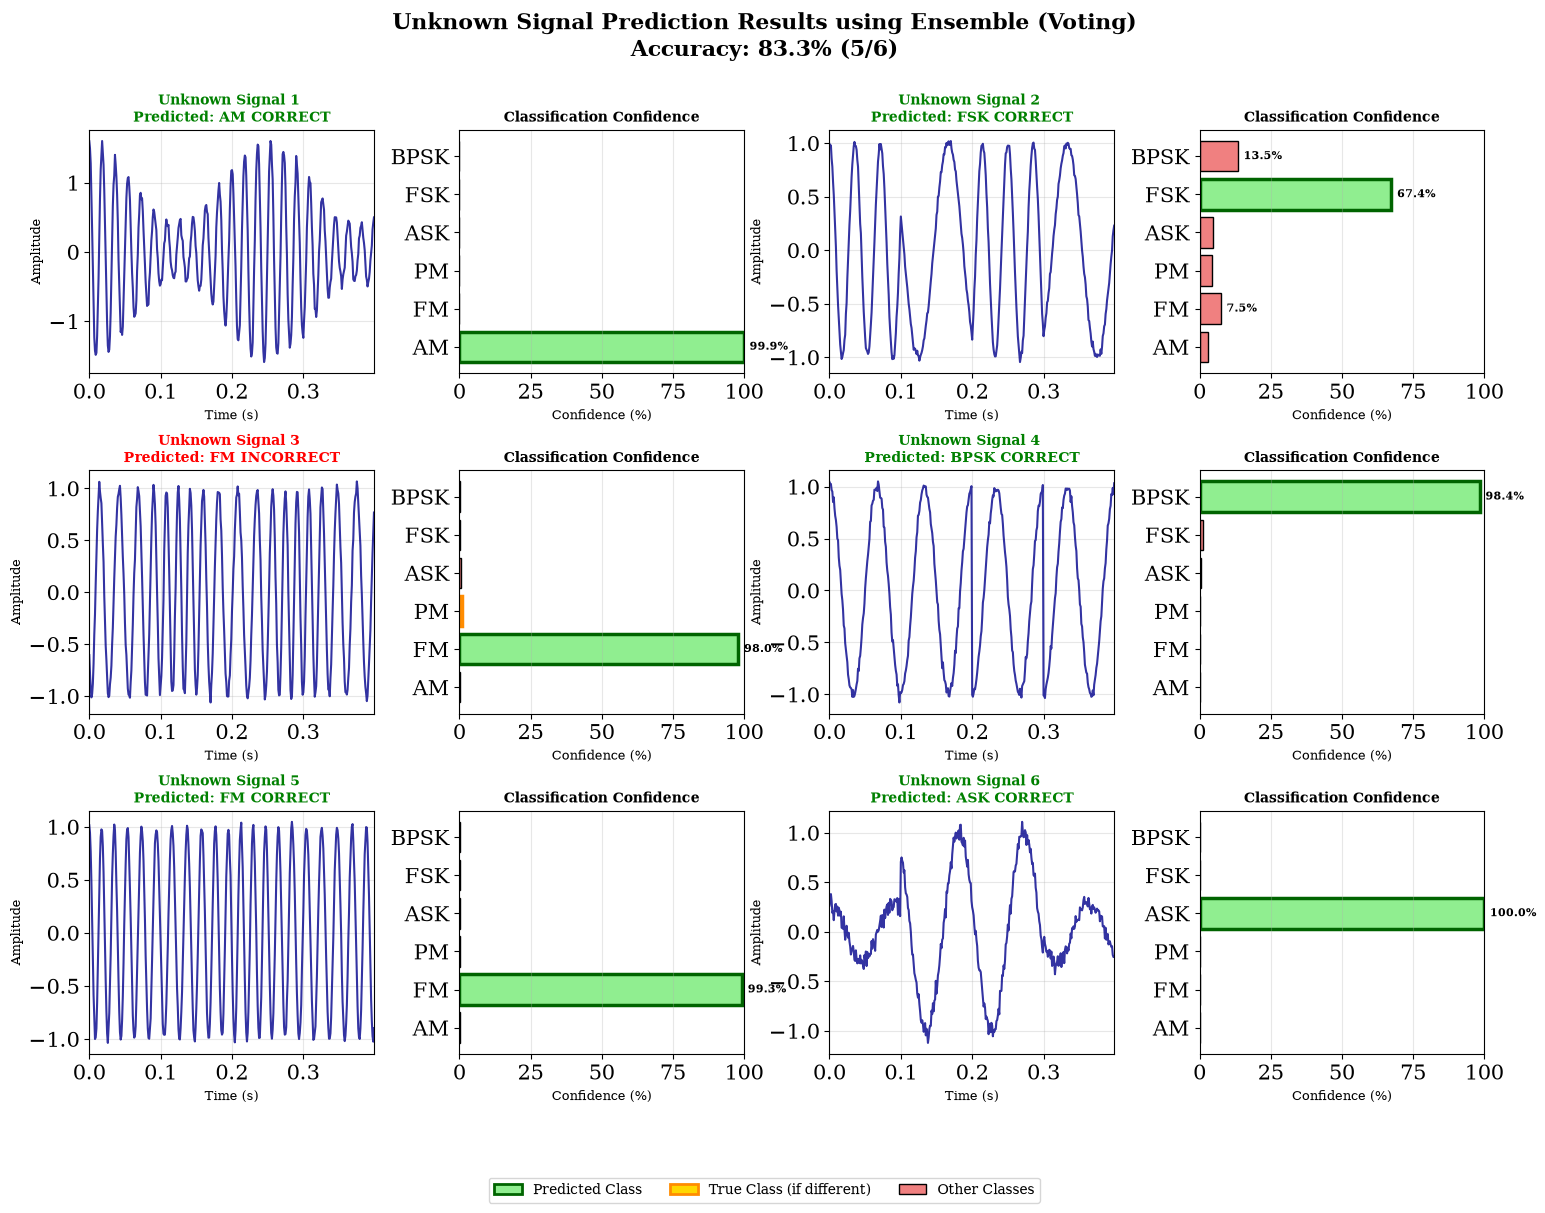


CONFUSION MATRIX FOR UNKNOWN SIGNALS


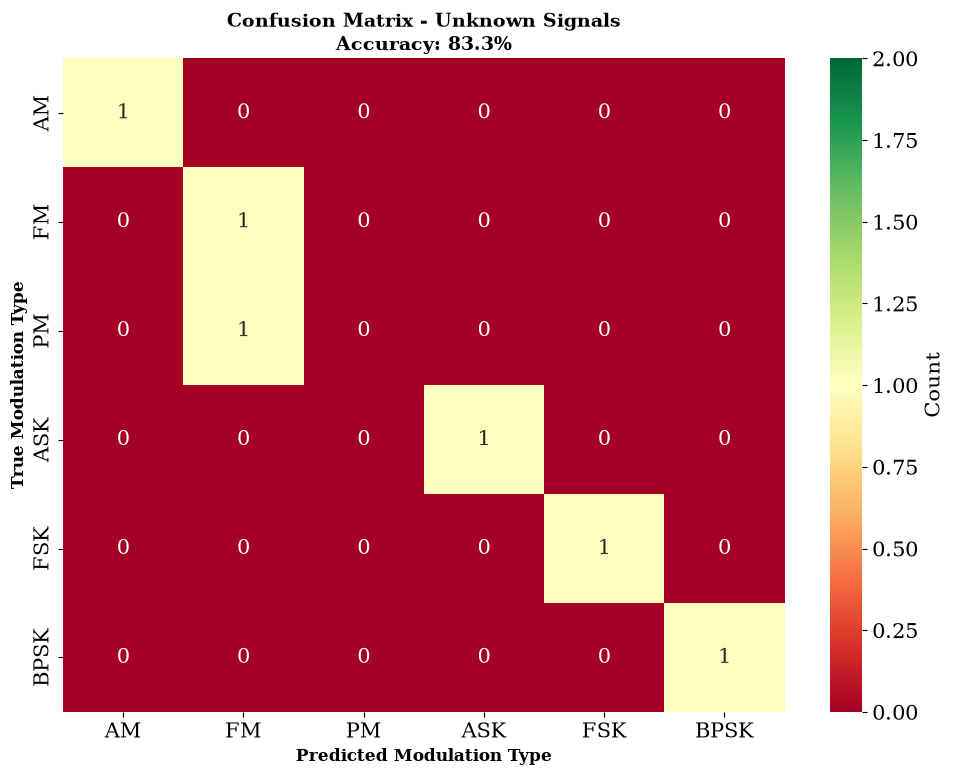

In [40]:
print("\n" + "="*70)
print("PART 4: PREDICTING UNKNOWN MODULATED SIGNALS")
print("="*70)

def predict_unknown_signal(signal, model, scaler, is_pca=False, pca_model=None):
    """
    Predict the modulation type of an unknown signal
    """
    # Extract features
    features = extract_enhanced_features(signal)
    features = np.array(features).reshape(1, -1)
    
    # Scale features
    features_scaled = scaler.transform(features)
    
    # Apply PCA if needed
    if is_pca and pca_model is not None:
        features_scaled = pca_model.transform(features_scaled)
    
    # Predict
    prediction = model.predict(features_scaled)[0]
    
    # Get probability if available
    if hasattr(model, 'predict_proba'):
        probabilities = model.predict_proba(features_scaled)[0]
    elif hasattr(model, 'decision_function'):
        # For standard SVM without probability
        decision = model.decision_function(features_scaled)[0]
        # Normalize to pseudo-probabilities
        exp_decision = np.exp(decision - np.max(decision))
        probabilities = exp_decision / np.sum(exp_decision)
    else:
        probabilities = None
    
    return prediction, probabilities

# Generate unknown test signals
print("\nGenerating unknown signals for prediction...\n")

# Signal 1: Unknown AM signal
t_unknown = np.linspace(0, 1, 1000)
fc_unknown = 55
fm_unknown = 4
_, _, unknown_am = amplitude_modulation(t_unknown, fc_unknown, fm_unknown, A_m=0.6)
unknown_am += 0.05 * np.random.randn(len(unknown_am))

# Signal 2: Unknown FSK signal
bits_unknown = np.array([1, 0, 1, 0, 1, 1, 0, 0])
t_fsk, unknown_fsk, _ = fsk_modulation(bits_unknown, f1=12, f2=28, fs=1000, samples_per_bit=100)
unknown_fsk += 0.02 * np.random.randn(len(unknown_fsk))

# Signal 3: Unknown PM signal
_, _, unknown_pm = phase_modulation(t_unknown, 48, 6, kp=2.2)
unknown_pm += 0.03 * np.random.randn(len(unknown_pm))

# Signal 4: Unknown BPSK signal
bits_bpsk = np.array([1, 1, 0, 1, 0, 0, 1, 1])
t_bpsk, unknown_bpsk, _ = psk_modulation(bits_bpsk, fc=15, fs=1000, samples_per_bit=100)
unknown_bpsk += 0.03 * np.random.randn(len(unknown_bpsk))

# Signal 5: Unknown FM signal
_, _, unknown_fm = frequency_modulation(t_unknown, 52, 4.5, kf=6)
unknown_fm += 0.02 * np.random.randn(len(unknown_fm))

# Signal 6: Unknown ASK signal
bits_ask = np.array([0, 1, 1, 0, 1, 0, 0, 1])
t_ask, unknown_ask, _ = ask_modulation(bits_ask, fc=11, fs=1000, samples_per_bit=100)
unknown_ask += 0.05 * np.random.randn(len(unknown_ask))

unknown_signals = [
    (unknown_am, t_unknown, "Unknown Signal 1 (Actually AM)", 0),
    (unknown_fsk, t_fsk, "Unknown Signal 2 (Actually FSK)", 4),
    (unknown_pm, t_unknown, "Unknown Signal 3 (Actually PM)", 2),
    (unknown_bpsk, t_bpsk, "Unknown Signal 4 (Actually BPSK)", 5),
    (unknown_fm, t_unknown, "Unknown Signal 5 (Actually FM)", 1),
    (unknown_ask, t_ask, "Unknown Signal 6 (Actually ASK)", 3)
]

# Determine if best model uses PCA
use_pca = (best_idx == 2)
pca_model_for_pred = pca_final if use_pca else None

# Make predictions
predictions_results = []

print("="*70)
print("PREDICTION RESULTS")
print("="*70)

for i, (signal, t_sig, label, true_class) in enumerate(unknown_signals, 1):
    pred_class, probabilities = predict_unknown_signal(
        signal, best_model, scaler, use_pca, pca_model_for_pred
    )
    
    predicted_modulation = class_names[pred_class]
    true_modulation = class_names[true_class]
    is_correct = (pred_class == true_class)
    
    predictions_results.append({
        'signal': signal,
        'time': t_sig,
        'label': label,
        'true_class': true_class,
        'pred_class': pred_class,
        'probabilities': probabilities,
        'is_correct': is_correct
    })
    
    print(f"\n{label}")
    print(f"  True Modulation: {true_modulation}")
    print(f"  Predicted: {predicted_modulation} {'CORRECT' if is_correct else 'INCORRECT'}")
    
    if probabilities is not None:
        print(f"  Confidence Scores:")
        for j, (mod_name, prob) in enumerate(zip(class_names, probabilities)):
            marker = "->" if j == pred_class else " "
            bar = "|" * int(prob * 40)
            print(f"    {marker} {mod_name:8s}: {prob*100:5.1f}% {bar}")

# Calculate accuracy on unknown signals
correct_predictions = sum([r['is_correct'] for r in predictions_results])
total_unknown = len(unknown_signals)
unknown_accuracy = (correct_predictions / total_unknown) * 100

print("\n" + "="*70)
print(f"Unknown Signal Classification: {correct_predictions}/{total_unknown} correct ({unknown_accuracy:.1f}%)")
print("="*70)

# ============================================================================
# VISUALIZATION OF UNKNOWN SIGNAL PREDICTIONS
# ============================================================================

fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 4, hspace=0.4, wspace=0.3)

for idx, result in enumerate(predictions_results):
    signal = result['signal']
    t_sig = result['time']
    label = result['label']
    pred_class = result['pred_class']
    true_class = result['true_class']
    probabilities = result['probabilities']
    is_correct = result['is_correct']
    
    # Signal plot (left column - spans 2 columns)
    ax_signal = fig.add_subplot(gs[idx // 2, (idx % 2) * 2])
    ax_signal.plot(t_sig[:400], signal[:400], linewidth=1.5, 
                   color='darkblue', alpha=0.8)
    
    title_color = 'green' if is_correct else 'red'
    title_symbol = 'CORRECT' if is_correct else 'INCORRECT'
    ax_signal.set_title(f'{label.split("(")[0]}\nPredicted: {class_names[pred_class]} {title_symbol}', 
                        fontsize=10, fontweight='bold', color=title_color)
    ax_signal.set_xlabel('Time (s)', fontsize=9)
    ax_signal.set_ylabel('Amplitude', fontsize=9)
    ax_signal.grid(True, alpha=0.3)
    ax_signal.set_xlim([0, t_sig[399]])
    
    # Probability plot (right column)
    ax_prob = fig.add_subplot(gs[idx // 2, (idx % 2) * 2 + 1])
    
    if probabilities is not None:
        colors_prob = ['lightcoral' if i != pred_class else 'lightgreen' 
                      for i in range(len(class_names))]
        if pred_class != true_class and true_class < len(class_names):
            colors_prob[true_class] = 'gold'
        
        bars = ax_prob.barh(class_names, probabilities * 100, 
                           color=colors_prob, edgecolor='black', linewidth=1)
        
        # Highlight predicted and true class
        bars[pred_class].set_edgecolor('darkgreen')
        bars[pred_class].set_linewidth(2.5)
        if pred_class != true_class:
            bars[true_class].set_edgecolor('darkorange')
            bars[true_class].set_linewidth(2.5)
        
        ax_prob.set_xlabel('Confidence (%)', fontsize=9)
        ax_prob.set_title('Classification Confidence', fontsize=10, fontweight='bold')
        ax_prob.set_xlim([0, 100])
        ax_prob.grid(axis='x', alpha=0.3)
        
        # Add percentage labels
        for i, (bar, prob) in enumerate(zip(bars, probabilities)):
            if prob > 0.05:
                ax_prob.text(prob * 100 + 2, i, f'{prob*100:.1f}%', 
                           va='center', fontsize=8, fontweight='bold')

fig.suptitle(f'Unknown Signal Prediction Results using {best_technique}\n'
             f'Accuracy: {unknown_accuracy:.1f}% ({correct_predictions}/{total_unknown})', 
             fontsize=16, fontweight='bold')

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='lightgreen', edgecolor='darkgreen', linewidth=2, label='Predicted Class'),
    Patch(facecolor='gold', edgecolor='darkorange', linewidth=2, label='True Class (if different)'),
    Patch(facecolor='lightcoral', edgecolor='black', label='Other Classes')
]
fig.legend(handles=legend_elements, loc='lower center', ncol=3, 
          bbox_to_anchor=(0.5, -0.02), fontsize=10, frameon=True)

plt.tight_layout()
plt.show()

# Additional detailed confusion matrix for unknown signals
print("\n" + "="*70)
print("CONFUSION MATRIX FOR UNKNOWN SIGNALS")
print("="*70)

y_true_unknown = [r['true_class'] for r in predictions_results]
y_pred_unknown = [r['pred_class'] for r in predictions_results]

cm_unknown = confusion_matrix(y_true_unknown, y_pred_unknown, labels=range(len(class_names)))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm_unknown, annot=True, fmt='d', cmap='RdYlGn', 
            xticklabels=class_names, yticklabels=class_names,
            ax=ax, cbar_kws={'label': 'Count'}, vmin=0, vmax=2)
ax.set_title(f'Confusion Matrix - Unknown Signals\nAccuracy: {unknown_accuracy:.1f}%', 
             fontsize=14, fontweight='bold')
ax.set_ylabel('True Modulation Type', fontsize=12, fontweight='bold')
ax.set_xlabel('Predicted Modulation Type', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()
